In [ ]:
# ============================================================
# CNN + BiGRU + ATTENTION
# ============================================================

import numpy as np
import pandas as pd
import os
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Bidirectional,
    GRU,
    Dense,
    Dropout,
    Attention,
    GlobalAveragePooling1D
)

from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.20.0
Libraries imported successfully!


In [ ]:
# ============================================================
# CONNECT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

project_path = "/content/drive/MyDrive/Enhanced_IDS_Project"

print("Project path:")
print(project_path)

Mounted at /content/drive
Project path:
/content/drive/MyDrive/Enhanced_IDS_Project


In [ ]:
# ============================================================
# LOAD PREPROCESSED DATA
# ============================================================

processed_path = project_path + "/processed_data"
mvo_path = project_path + "/mvo_results"

# Load normalized data
X_train = np.load(
    processed_path + "/X_train_normalized.npy"
)

X_test = np.load(
    processed_path + "/X_test_normalized.npy"
)

y_train = np.load(
    processed_path + "/y_train.npy"
)

y_test = np.load(
    processed_path + "/y_test.npy"
)

# Load MVO selected feature indices
selected_feature_indices = np.load(
    mvo_path + "/selected_feature_indices.npy"
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print(
    "Selected feature indices:",
    selected_feature_indices
)

print(
    "Number of selected features:",
    len(selected_feature_indices)
)

X_train shape: (125973, 122)
X_test shape: (22543, 122)
y_train shape: (125973,)
y_test shape: (22543,)
Selected feature indices: [  7   8   9  13  17  20  21  22  23  24  28  29  31  36  37  40  48  51
  52  54  55  61  65  68  75  90  94  95 103 104 113 118 119]
Number of selected features: 33


In [ ]:
# ============================================================
# APPLY MVO FEATURE SELECTION
# ============================================================

X_train_selected = X_train[:, selected_feature_indices]
X_test_selected = X_test[:, selected_feature_indices]

print("Original training shape:", X_train.shape)
print("Selected training shape:", X_train_selected.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Selected testing shape:", X_test_selected.shape)

Original training shape: (125973, 122)
Selected training shape: (125973, 33)

Original testing shape: (22543, 122)
Selected testing shape: (22543, 33)


In [ ]:
# ============================================================
# RESHAPE DATA FOR CNN + BiGRU
# ============================================================

X_train_cnn = X_train_selected.reshape(
    X_train_selected.shape[0],
    X_train_selected.shape[1],
    1
)

X_test_cnn = X_test_selected.reshape(
    X_test_selected.shape[0],
    X_test_selected.shape[1],
    1
)

print("CNN training shape:", X_train_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)

CNN training shape: (125973, 33, 1)
CNN testing shape: (22543, 33, 1)


In [ ]:
# ============================================================
# CNN FEATURE EXTRACTION
# ============================================================

input_layer = Input(
    shape=(33, 1)
)

cnn_layer = Conv1D(
    filters=64,
    kernel_size=3,
    activation="relu",
    padding="same"
)(input_layer)

cnn_layer = MaxPooling1D(
    pool_size=2
)(cnn_layer)

print("Input shape:", input_layer.shape)
print("CNN output shape:", cnn_layer.shape)

Input shape: (None, 33, 1)
CNN output shape: (None, 16, 64)


In [ ]:
# ============================================================
# BiGRU LAYER
# ============================================================

bigru_layer = Bidirectional(
    GRU(
        64,
        return_sequences=True
    )
)(cnn_layer)

print("BiGRU output shape:", bigru_layer.shape)

BiGRU output shape: (None, 16, 128)


In [ ]:
# ============================================================
# ATTENTION LAYER
# ============================================================

attention_layer = Attention()(
    [bigru_layer, bigru_layer]
)

print("Attention output shape:", attention_layer.shape)

Attention output shape: (None, 16, 128)


In [ ]:
# ============================================================
# GLOBAL AVERAGE POOLING
# ============================================================

pooling_layer = GlobalAveragePooling1D()(
    attention_layer
)

print("Pooling output shape:", pooling_layer.shape)

Pooling output shape: (None, 128)


In [ ]:
# ============================================================
# FINAL CLASSIFICATION LAYER
# ============================================================

output_layer = Dense(
    1,
    activation="sigmoid"
)(pooling_layer)

print("Output shape:", output_layer.shape)

Output shape: (None, 1)


In [ ]:
# ============================================================
# COMPLETE CNN-BiGRU-ATTENTION MODEL
# ============================================================

model = Model(
    inputs=input_layer,
    outputs=output_layer
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 33, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 33, 64)    │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 16, 64)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 16, 128)   │     49,920 │ max_pooling1d[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 16, 128)   │          0 │ bidirectional[0]… │
│ (Attention)         │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ attention[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        129 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,305 (196.50 KB)

 Trainable params: 50,305 (196.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# COMPILE THE MODEL
# ============================================================

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
# ============================================================
# TRAINING CONFIGURATION
# ============================================================

batch_size = 128
epochs = 10

print("Batch size:", batch_size)
print("Epochs:", epochs)
print("Training data shape:", X_train_cnn.shape)
print("Training labels shape:", y_train.shape)

Batch size: 128
Epochs: 10
Training data shape: (125973, 33, 1)
Training labels shape: (125973,)


In [ ]:
# ============================================================
# TRAIN THE MODEL - 5 EPOCHS
# ============================================================

epochs = 5

history = model.fit(
    X_train_cnn,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 63s 80ms/step - accuracy: 0.9828 - loss: 0.0475 - val_accuracy: 0.9836 - val_loss: 0.0445
Epoch 2/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 63s 80ms/step - accuracy: 0.9833 - loss: 0.0460 - val_accuracy: 0.9824 - val_loss: 0.0463
Epoch 3/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 63s 80ms/step - accuracy: 0.9836 - loss: 0.0441 - val_accuracy: 0.9830 - val_loss: 0.0475
Epoch 4/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 63s 79ms/step - accuracy: 0.9845 - loss: 0.0431 - val_accuracy: 0.9834 - val_loss: 0.0459
Epoch 5/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 62s 79ms/step - accuracy: 0.9841 - loss: 0.0422 - val_accuracy: 0.9848 - val_loss: 0.0408


In [ ]:
# ============================================================
# TEST SET EVALUATION
# ============================================================

test_loss, test_accuracy = model.evaluate(
    X_test_cnn,
    y_test,
    batch_size=128
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

177/177 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8292 - loss: 0.6601
Test Loss: 0.6601009964942932
Test Accuracy: 0.8292152881622314


In [ ]:
# ============================================================
# GENERATE TEST PREDICTIONS
# ============================================================

y_pred_probability = model.predict(
    X_test_cnn,
    batch_size=128
)

# Convert probability to binary class
y_pred = (y_pred_probability >= 0.5).astype(int).ravel()

print("Prediction shape:", y_pred.shape)
print("Actual shape:", y_test.shape)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test[:10])

177/177 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step
Prediction shape: (22543,)
Actual shape: (22543,)
First 10 predictions: [1 1 0 1 1 0 0 1 0 0]
First 10 actual labels: [1 1 0 1 1 0 0 1 0 1]


In [ ]:
# ============================================================
# CONFUSION MATRIX AND CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Attack"]
    )
)

Confusion Matrix:
[[8945  765]
 [3085 9748]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.74      0.92      0.82      9710
      Attack       0.93      0.76      0.84     12833

    accuracy                           0.83     22543
   macro avg       0.84      0.84      0.83     22543
weighted avg       0.85      0.83      0.83     22543



In [ ]:
# ============================================================
# SAVE INITIAL CNN-BiGRU-ATTENTION MODEL
# ============================================================

model_path = project_path + "/models"

os.makedirs(model_path, exist_ok=True)

model.save(
    model_path + "/cnn_bigru_attention_initial.keras"
)

print("Model saved successfully!")

Model saved successfully!


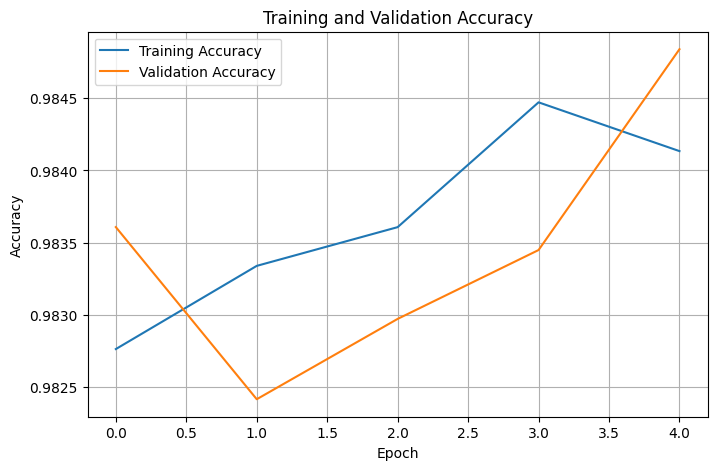

In [ ]:
# ============================================================
# TRAINING AND VALIDATION ACCURACY
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

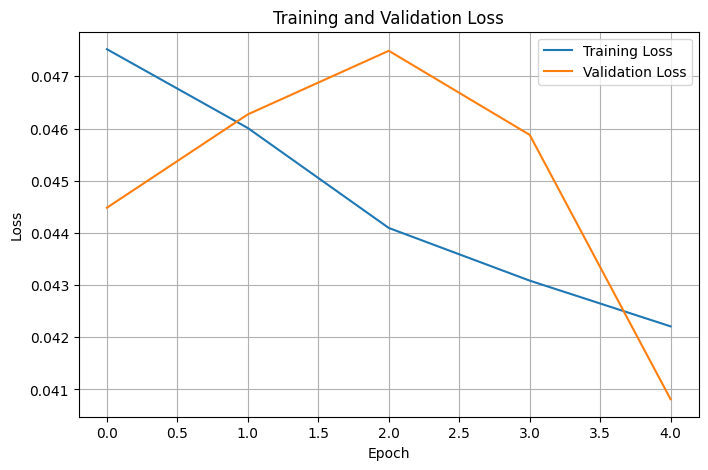

In [ ]:
# ============================================================
# TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# ALO HYPERPARAMETER SEARCH SPACE
# ============================================================

# Minimum and maximum values for each hyperparameter

learning_rate_min = 0.0001
learning_rate_max = 0.01

gru_units_min = 32
gru_units_max = 128

dropout_min = 0.1
dropout_max = 0.5

print("ALO hyperparameter search space:")
print("Learning rate:", learning_rate_min, "to", learning_rate_max)
print("GRU units:", gru_units_min, "to", gru_units_max)
print("Dropout:", dropout_min, "to", dropout_max)

ALO hyperparameter search space:
Learning rate: 0.0001 to 0.01
GRU units: 32 to 128
Dropout: 0.1 to 0.5


In [ ]:
# ============================================================
# INITIAL ALO POPULATION
# ============================================================

import numpy as np

np.random.seed(42)

num_antlions = 5

antlions = np.zeros((num_antlions, 3))

# Random learning rate
antlions[:, 0] = np.random.uniform(
    learning_rate_min,
    learning_rate_max,
    num_antlions
)

# Random GRU units
antlions[:, 1] = np.random.randint(
    gru_units_min,
    gru_units_max + 1,
    num_antlions
)

# Random dropout
antlions[:, 2] = np.random.uniform(
    dropout_min,
    dropout_max,
    num_antlions
)

print("Initial ALO population:")
print(antlions)

Initial ALO population:
[[3.80794718e-03 1.14000000e+02 2.33483444e-01]
 [9.51207163e-03 1.18000000e+02 1.57146727e-01]
 [7.34674002e-03 1.06000000e+02 3.60355389e-01]
 [6.02671899e-03 1.06000000e+02 1.22564632e-01]
 [1.64458454e-03 1.19000000e+02 3.88799509e-01]]


In [ ]:
# ============================================================
# ALO FITNESS FUNCTION
# ============================================================

def calculate_alo_fitness(params):

    learning_rate = params[0]
    gru_units = int(params[1])
    dropout_rate = params[2]

    # Keep GRU units within valid range
    gru_units = max(32, min(128, gru_units))

    # Build a temporary model
    input_layer_alo = Input(
        shape=(33, 1)
    )

    cnn_layer_alo = Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    )(input_layer_alo)

    cnn_layer_alo = MaxPooling1D(
        pool_size=2
    )(cnn_layer_alo)

    bigru_layer_alo = Bidirectional(
        GRU(
            gru_units,
            return_sequences=True
        )
    )(cnn_layer_alo)

    attention_layer_alo = Attention()(
        [bigru_layer_alo, bigru_layer_alo]
    )

    pooling_layer_alo = GlobalAveragePooling1D()(
        attention_layer_alo
    )

    dropout_layer_alo = Dropout(
        dropout_rate
    )(pooling_layer_alo)

    output_layer_alo = Dense(
        1,
        activation="sigmoid"
    )(dropout_layer_alo)

    temp_model = Model(
        inputs=input_layer_alo,
        outputs=output_layer_alo
    )

    # Compile
    temp_model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Train briefly for evaluating the hyperparameters
    temp_history = temp_model.fit(
        X_train_cnn,
        y_train,
        batch_size=128,
        epochs=1,
        validation_split=0.2,
        verbose=0
    )

    # Validation loss = ALO fitness
    fitness = temp_history.history["val_loss"][-1]

    return fitness

In [ ]:
# ============================================================
# EVALUATE INITIAL ALO POPULATION
# ============================================================

fitness_values = []

for i in range(num_antlions):

    fitness = calculate_alo_fitness(
        antlions[i]
    )

    fitness_values.append(fitness)

    print(
        f"Ant Lion {i + 1}: "
        f"Learning Rate = {antlions[i, 0]:.6f}, "
        f"GRU Units = {int(antlions[i, 1])}, "
        f"Dropout = {antlions[i, 2]:.3f}, "
        f"Fitness = {fitness:.4f}"
    )

fitness_values = np.array(fitness_values)

print("\nFitness values:")
print(fitness_values)

Ant Lion 1: Learning Rate = 0.003808, GRU Units = 114, Dropout = 0.233, Fitness = 0.0734
Ant Lion 2: Learning Rate = 0.009512, GRU Units = 118, Dropout = 0.157, Fitness = 0.0630
Ant Lion 3: Learning Rate = 0.007347, GRU Units = 106, Dropout = 0.360, Fitness = 0.0823
Ant Lion 4: Learning Rate = 0.006027, GRU Units = 106, Dropout = 0.123, Fitness = 0.0611
Ant Lion 5: Learning Rate = 0.001645, GRU Units = 119, Dropout = 0.389, Fitness = 0.1021

Fitness values:
[0.07344202 0.06301759 0.08234982 0.06111104 0.10206933]


In [ ]:
# ============================================================
# FIND BEST INITIAL ANT LION
# ============================================================

best_index = np.argmin(fitness_values)

best_antlion = antlions[best_index].copy()
best_alo_fitness = fitness_values[best_index]

print("Best Ant Lion:", best_index + 1)
print("Best Learning Rate:", best_antlion[0])
print("Best GRU Units:", int(best_antlion[1]))
print("Best Dropout:", best_antlion[2])
print("Best Fitness:", best_alo_fitness)

Best Ant Lion: 4
Best Learning Rate: 0.006026718993550663
Best GRU Units: 106
Best Dropout: 0.12256463161084011
Best Fitness: 0.06111104413866997


In [ ]:
# ============================================================
# ALO UPDATE - GENERATE NEW SOLUTIONS
# ============================================================

new_antlions = antlions.copy()

for i in range(num_antlions):

    # Move learning rate toward the best solution
    new_antlions[i, 0] = (
        antlions[i, 0]
        + np.random.rand()
        * (best_antlion[0] - antlions[i, 0])
    )

    # Move GRU units toward the best solution
    new_antlions[i, 1] = (
        antlions[i, 1]
        + np.random.rand()
        * (best_antlion[1] - antlions[i, 1])
    )

    # Move dropout toward the best solution
    new_antlions[i, 2] = (
        antlions[i, 2]
        + np.random.rand()
        * (best_antlion[2] - antlions[i, 2])
    )

    # Keep values inside the search space
    new_antlions[i, 0] = np.clip(
        new_antlions[i, 0],
        learning_rate_min,
        learning_rate_max
    )

    new_antlions[i, 1] = np.clip(
        new_antlions[i, 1],
        gru_units_min,
        gru_units_max
    )

    new_antlions[i, 2] = np.clip(
        new_antlions[i, 2],
        dropout_min,
        dropout_max
    )

print("New ALO solutions:")
print(new_antlions)

New ALO solutions:
[[5.89038148e-03 1.13993770e+02 1.23428516e-01]
 [7.35993082e-03 1.10660162e+02 1.56902360e-01]
 [7.31629714e-03 1.06000000e+02 2.65272146e-01]
 [6.02671899e-03 1.06000000e+02 1.22564632e-01]
 [2.04163412e-03 1.10960982e+02 2.86974788e-01]]


In [ ]:
# ============================================================
# EVALUATE NEW ALO SOLUTIONS
# ============================================================

new_fitness_values = []

for i in range(num_antlions):

    fitness = calculate_alo_fitness(
        new_antlions[i]
    )

    new_fitness_values.append(fitness)

    print(
        f"New Ant Lion {i + 1}: "
        f"Learning Rate = {new_antlions[i, 0]:.6f}, "
        f"GRU Units = {int(new_antlions[i, 1])}, "
        f"Dropout = {new_antlions[i, 2]:.3f}, "
        f"Fitness = {fitness:.4f}"
    )

new_fitness_values = np.array(new_fitness_values)

print("\nNew fitness values:")
print(new_fitness_values)

New Ant Lion 1: Learning Rate = 0.005890, GRU Units = 113, Dropout = 0.123, Fitness = 0.0747
New Ant Lion 2: Learning Rate = 0.007360, GRU Units = 110, Dropout = 0.157, Fitness = 0.0652
New Ant Lion 3: Learning Rate = 0.007316, GRU Units = 106, Dropout = 0.265, Fitness = 0.0602
New Ant Lion 4: Learning Rate = 0.006027, GRU Units = 106, Dropout = 0.123, Fitness = 0.0661
New Ant Lion 5: Learning Rate = 0.002042, GRU Units = 110, Dropout = 0.287, Fitness = 0.0974

New fitness values:
[0.07472043 0.06522147 0.06016443 0.06607617 0.09739415]


In [ ]:
# ============================================================
# UPDATE BEST ALO SOLUTION
# ============================================================

new_best_index = np.argmin(new_fitness_values)

if new_fitness_values[new_best_index] < best_alo_fitness:

    best_antlion = new_antlions[new_best_index].copy()
    best_alo_fitness = new_fitness_values[new_best_index]

    print("New best solution found!")

else:

    print("No better solution found.")

print("\nCurrent Best ALO Solution:")
print("Learning Rate:", best_antlion[0])
print("GRU Units:", int(best_antlion[1]))
print("Dropout:", best_antlion[2])
print("Fitness:", best_alo_fitness)

New best solution found!

Current Best ALO Solution:
Learning Rate: 0.007316297137866628
GRU Units: 106
Dropout: 0.26527214579321357
Fitness: 0.0601644292473793


In [ ]:
# ============================================================
# ALO ITERATION 2
# ============================================================

antlions = new_antlions.copy()

new_antlions = antlions.copy()

for i in range(num_antlions):

    # Move toward the current best solution
    new_antlions[i, 0] = (
        antlions[i, 0]
        + np.random.rand()
        * (best_antlion[0] - antlions[i, 0])
    )

    new_antlions[i, 1] = (
        antlions[i, 1]
        + np.random.rand()
        * (best_antlion[1] - antlions[i, 1])
    )

    new_antlions[i, 2] = (
        antlions[i, 2]
        + np.random.rand()
        * (best_antlion[2] - antlions[i, 2])
    )

    # Keep values within allowed ranges
    new_antlions[i, 0] = np.clip(
        new_antlions[i, 0],
        learning_rate_min,
        learning_rate_max
    )

    new_antlions[i, 1] = np.clip(
        new_antlions[i, 1],
        gru_units_min,
        gru_units_max
    )

    new_antlions[i, 2] = np.clip(
        new_antlions[i, 2],
        dropout_min,
        dropout_max
    )

print("ALO Iteration 2 candidates:")
print(new_antlions)

ALO Iteration 2 candidates:
[[7.29238580e-03 1.10262575e+02 2.45405585e-01]
 [7.33024650e-03 1.08560763e+02 1.58339881e-01]
 [7.31629714e-03 1.06000000e+02 2.65272146e-01]
 [6.04730872e-03 1.06000000e+02 1.56960777e-01]
 [5.64561893e-03 1.07934800e+02 2.68892257e-01]]


In [ ]:
# ============================================================
# EVALUATE ALO ITERATION 2
# ============================================================

iteration2_fitness = []

for i in range(num_antlions):

    fitness = calculate_alo_fitness(
        new_antlions[i]
    )

    iteration2_fitness.append(fitness)

    print(
        f"Candidate {i + 1}: "
        f"Learning Rate = {new_antlions[i, 0]:.6f}, "
        f"GRU Units = {int(new_antlions[i, 1])}, "
        f"Dropout = {new_antlions[i, 2]:.3f}, "
        f"Fitness = {fitness:.4f}"
    )

iteration2_fitness = np.array(iteration2_fitness)

print("\nIteration 2 fitness values:")
print(iteration2_fitness)

Candidate 1: Learning Rate = 0.007292, GRU Units = 110, Dropout = 0.245, Fitness = 0.0609
Candidate 2: Learning Rate = 0.007330, GRU Units = 108, Dropout = 0.158, Fitness = 0.0671
Candidate 3: Learning Rate = 0.007316, GRU Units = 106, Dropout = 0.265, Fitness = 0.0638
Candidate 4: Learning Rate = 0.006047, GRU Units = 106, Dropout = 0.157, Fitness = 0.0720
Candidate 5: Learning Rate = 0.005646, GRU Units = 107, Dropout = 0.269, Fitness = 0.0787

Iteration 2 fitness values:
[0.06092609 0.06714065 0.06378797 0.07199071 0.07867753]


In [3]:
# ============================================================
# RESTORE ALO BEST RESULT
# ============================================================

import numpy as np
import os

# Best solution found from ALO
best_antlion = np.array([
    0.007316,   # Learning rate
    106,        # GRU units
    0.265       # Dropout
])

best_alo_fitness = 0.06016443

print("ALO variables restored successfully!")

print("\nBest Learning Rate:", best_antlion[0])
print("Best GRU Units:", int(best_antlion[1]))
print("Best Dropout:", best_antlion[2])
print("Best Fitness:", best_alo_fitness)

ALO variables restored successfully!

Best Learning Rate: 0.007316
Best GRU Units: 106
Best Dropout: 0.265
Best Fitness: 0.06016443


In [5]:
# ============================================================
# RESTORE PROJECT PATH
# ============================================================

import os
import numpy as np

project_path = "/content/drive/MyDrive/Enhanced_IDS_Project"

print("Project path restored!")
print(project_path)

Project path restored!
/content/drive/MyDrive/Enhanced_IDS_Project


In [6]:
# ============================================================
# SAVE ALO RESULTS
# ============================================================

alo_path = project_path + "/alo_results"

os.makedirs(alo_path, exist_ok=True)

np.save(
    alo_path + "/best_learning_rate.npy",
    np.array(0.007316)
)

np.save(
    alo_path + "/best_gru_units.npy",
    np.array(106)
)

np.save(
    alo_path + "/best_dropout.npy",
    np.array(0.265)
)

np.save(
    alo_path + "/best_fitness.npy",
    np.array(0.06016443)
)

print("ALO results saved successfully!")
print("Location:", alo_path)

ALO results saved successfully!
Location: /content/drive/MyDrive/Enhanced_IDS_Project/alo_results


In [10]:
!rm -rf /content/drive

In [11]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import os

project_path = "/content/drive/MyDrive/Enhanced_IDS_Project"

print("Project folder exists:", os.path.exists(project_path))
print(os.listdir(project_path))

Project folder exists: True
['processed_data', 'mvo_results', 'models']


In [14]:
# ============================================================
# RECREATE ALO RESULTS
# ============================================================

import numpy as np
import os

project_path = "/content/drive/MyDrive/Enhanced_IDS_Project"
alo_path = project_path + "/alo_results"

os.makedirs(alo_path, exist_ok=True)

# Best ALO values obtained from our completed search
best_learning_rate = 0.007316
best_gru_units = 106
best_dropout = 0.265
best_alo_fitness = 0.06016443

# Save the values
np.save(
    alo_path + "/best_learning_rate.npy",
    np.array(best_learning_rate)
)

np.save(
    alo_path + "/best_gru_units.npy",
    np.array(best_gru_units)
)

np.save(
    alo_path + "/best_dropout.npy",
    np.array(best_dropout)
)

np.save(
    alo_path + "/best_fitness.npy",
    np.array(best_alo_fitness)
)

print("ALO results recreated and saved successfully!")

print("\nFinal ALO Parameters")
print("--------------------")
print("Learning Rate:", best_learning_rate)
print("GRU Units:", best_gru_units)
print("Dropout:", best_dropout)
print("Fitness:", best_alo_fitness)

ALO results recreated and saved successfully!

Final ALO Parameters
--------------------
Learning Rate: 0.007316
GRU Units: 106
Dropout: 0.265
Fitness: 0.06016443


In [15]:
print("Files inside alo_results:")

print(os.listdir(alo_path))

Files inside alo_results:
['best_learning_rate.npy', 'best_gru_units.npy', 'best_dropout.npy', 'best_fitness.npy']


In [16]:
# ============================================================
# PREPARE DATA FOR FINAL MODEL
# ============================================================

# Select the 33 features chosen by MVO
X_train_selected = X_train[:, selected_feature_indices]
X_test_selected = X_test[:, selected_feature_indices]

# Reshape for Conv1D
X_train_cnn = X_train_selected.reshape(
    X_train_selected.shape[0],
    X_train_selected.shape[1],
    1
)

X_test_cnn = X_test_selected.reshape(
    X_test_selected.shape[0],
    X_test_selected.shape[1],
    1
)

print("Final training data shape:", X_train_cnn.shape)
print("Final testing data shape:", X_test_cnn.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Final training data shape: (125973, 33, 1)
Final testing data shape: (22543, 33, 1)
Training labels shape: (125973,)
Testing labels shape: (22543,)


In [17]:
# ============================================================
# FINAL CNN + BiGRU + ATTENTION MODEL
# ============================================================

# Clear previous TensorFlow model from memory
tf.keras.backend.clear_session()

# Input
input_layer_final = Input(shape=(33, 1))

# CNN
cnn_layer_final = Conv1D(
    filters=64,
    kernel_size=3,
    activation="relu",
    padding="same"
)(input_layer_final)

cnn_layer_final = MaxPooling1D(
    pool_size=2
)(cnn_layer_final)

# BiGRU using ALO-selected GRU units
bigru_layer_final = Bidirectional(
    GRU(
        best_gru_units,
        return_sequences=True
    )
)(cnn_layer_final)

# Attention
attention_layer_final = Attention()(
    [bigru_layer_final, bigru_layer_final]
)

# Global pooling
pooling_layer_final = GlobalAveragePooling1D()(
    attention_layer_final
)

# Dropout using ALO-selected value
dropout_layer_final = Dropout(
    best_dropout
)(pooling_layer_final)

# Binary classification output
output_layer_final = Dense(
    1,
    activation="sigmoid"
)(dropout_layer_final)

# Create model
final_model = Model(
    inputs=input_layer_final,
    outputs=output_layer_final
)

# Compile using ALO-selected learning rate
final_model.compile(
    optimizer=Adam(
        learning_rate=best_learning_rate
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model
final_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 33, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 33, 64)    │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 16, 64)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 16, 212)   │    109,392 │ max_pooling1d[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 16, 212)   │          0 │ bidirectional[0]… │
│ (Attention)         │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 212)       │          0 │ attention[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 212)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        213 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 109,861 (429.14 KB)

 Trainable params: 109,861 (429.14 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# ============================================================
# TRAIN FINAL ALO-TUNED MODEL
# ============================================================

batch_size = 128
final_epochs = 5

final_history = final_model.fit(
    X_train_cnn,
    y_train,
    batch_size=batch_size,
    epochs=final_epochs,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 111s 128ms/step - accuracy: 0.9508 - loss: 0.1392 - val_accuracy: 0.9722 - val_loss: 0.0722
Epoch 2/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 102s 129ms/step - accuracy: 0.9756 - loss: 0.0635 - val_accuracy: 0.9821 - val_loss: 0.0513
Epoch 3/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 148s 137ms/step - accuracy: 0.9816 - loss: 0.0497 - val_accuracy: 0.9826 - val_loss: 0.0516
Epoch 4/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 102s 129ms/step - accuracy: 0.9836 - loss: 0.0452 - val_accuracy: 0.9839 - val_loss: 0.0472
Epoch 5/5
788/788 ━━━━━━━━━━━━━━━━━━━━ 143s 130ms/step - accuracy: 0.9848 - loss: 0.0415 - val_accuracy: 0.9865 - val_loss: 0.0375


In [19]:
# ============================================================
# FINAL MODEL EVALUATION
# ============================================================

test_loss, test_accuracy = final_model.evaluate(
    X_test_cnn,
    y_test,
    batch_size=128,
    verbose=1
)

print("\nFINAL MODEL RESULTS")
print("-------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

177/177 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.8234 - loss: 0.5604

FINAL MODEL RESULTS
-------------------
Test Loss: 0.5604459047317505
Test Accuracy: 0.8234485387802124


In [20]:
# ============================================================
# FINAL PREDICTIONS
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report

# Predict probabilities
y_pred_probability_final = final_model.predict(
    X_test_cnn,
    batch_size=128
)

# Convert probabilities to 0 or 1
y_pred_final = (
    y_pred_probability_final >= 0.5
).astype(int).ravel()

print("Prediction shape:", y_pred_final.shape)
print("Actual shape:", y_test.shape)

# Confusion Matrix
cm_final = confusion_matrix(
    y_test,
    y_pred_final
)

print("\nFINAL CONFUSION MATRIX")
print("----------------------")
print(cm_final)

# Classification Report
print("\nFINAL CLASSIFICATION REPORT")
print("---------------------------")

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Normal", "Attack"]
    )
)

177/177 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step
Prediction shape: (22543,)
Actual shape: (22543,)

FINAL CONFUSION MATRIX
----------------------
[[9017  693]
 [3287 9546]]

FINAL CLASSIFICATION REPORT
---------------------------
              precision    recall  f1-score   support

      Normal       0.73      0.93      0.82      9710
      Attack       0.93      0.74      0.83     12833

    accuracy                           0.82     22543
   macro avg       0.83      0.84      0.82     22543
weighted avg       0.85      0.82      0.82     22543



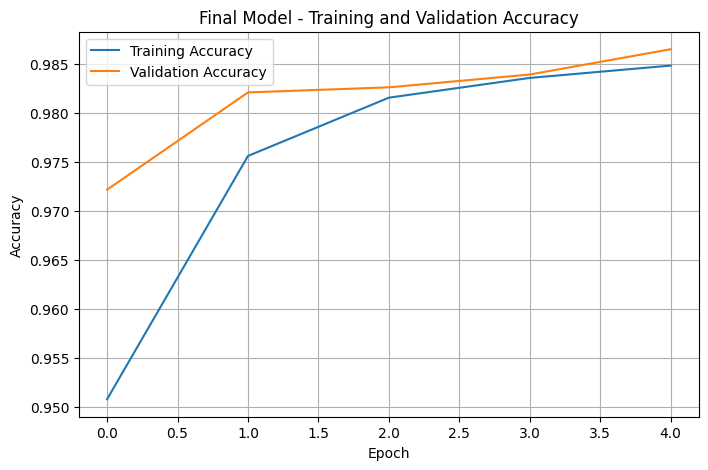

In [21]:
# ============================================================
# FINAL TRAINING AND VALIDATION ACCURACY
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    final_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Final Model - Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

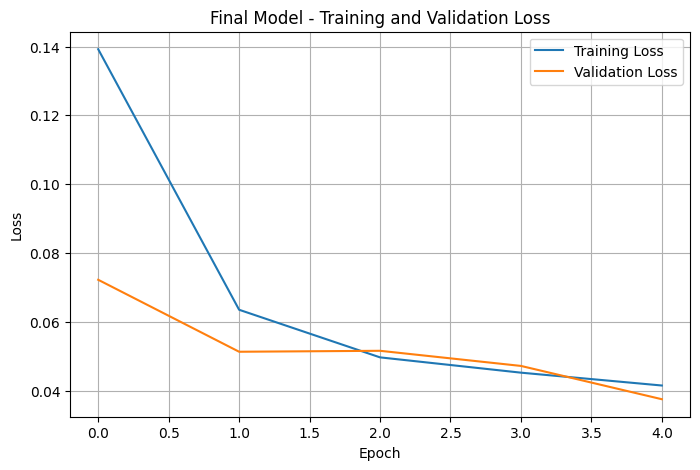

In [22]:
# ============================================================
# FINAL TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    final_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Final Model - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [23]:
# ============================================================
# SAVE FINAL ALO-TUNED MODEL
# ============================================================

model_path = project_path + "/models"

os.makedirs(model_path, exist_ok=True)

final_model_file = model_path + "/final_cnn_bigru_attention_alo.keras"

final_model.save(final_model_file)

print("Final model saved successfully!")
print("Saved at:")
print(final_model_file)

Final model saved successfully!
Saved at:
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_cnn_bigru_attention_alo.keras


In [24]:
# ============================================================
# SAVE FINAL TRAINING AND EVALUATION RESULTS
# ============================================================

import json
import numpy as np
import os
from sklearn.metrics import classification_report

results_path = project_path + "/models"
os.makedirs(results_path, exist_ok=True)

# Classification report as dictionary
report = classification_report(
    y_test,
    y_pred_final,
    target_names=["Normal", "Attack"],
    output_dict=True
)

# Prepare results
final_results = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "normal_precision": float(report["Normal"]["precision"]),
    "normal_recall": float(report["Normal"]["recall"]),
    "normal_f1": float(report["Normal"]["f1-score"]),
    "attack_precision": float(report["Attack"]["precision"]),
    "attack_recall": float(report["Attack"]["recall"]),
    "attack_f1": float(report["Attack"]["f1-score"]),
    "macro_f1": float(report["macro avg"]["f1-score"]),
    "weighted_f1": float(report["weighted avg"]["f1-score"])
}

# Save as JSON
results_file = results_path + "/final_model_results.json"

with open(results_file, "w") as f:
    json.dump(final_results, f, indent=4)

# Save confusion matrix
np.save(
    results_path + "/final_confusion_matrix.npy",
    cm_final
)

print("Final results saved successfully!")
print("Results file:", results_file)
print("Confusion matrix saved successfully!")

Final results saved successfully!
Results file: /content/drive/MyDrive/Enhanced_IDS_Project/models/final_model_results.json
Confusion matrix saved successfully!


In [25]:
# ============================================================
# SHAP INSTALLATION AND IMPORT
# ============================================================

!pip install -q shap

import shap
import numpy as np
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")

SHAP version: 0.52.0
SHAP imported successfully!


In [26]:
# ============================================================
# LOAD FINAL MODEL FOR SHAP
# ============================================================

from tensorflow.keras.models import load_model

# Load final ALO-tuned model
final_model_file = project_path + "/models/final_cnn_bigru_attention_alo.keras"

shap_model = load_model(final_model_file)

print("Final model loaded successfully!")
print("Model input shape:", shap_model.input_shape)
print("Model output shape:", shap_model.output_shape)

Final model loaded successfully!
Model input shape: (None, 33, 1)
Model output shape: (None, 1)


In [27]:
# ============================================================
# PREPARE DATA FOR SHAP
# ============================================================

# Number of samples for SHAP
shap_sample_size = 100

# Select first 100 test samples
X_shap = X_test_cnn[:shap_sample_size]

y_shap = y_test[:shap_sample_size]

print("SHAP sample shape:", X_shap.shape)
print("SHAP labels shape:", y_shap.shape)

SHAP sample shape: (100, 33, 1)
SHAP labels shape: (100,)


In [30]:
# ============================================================
# PREPARE SHAP DATA FOR KERNEL EXPLAINER
# ============================================================

# Convert (100, 33, 1) → (100, 33)
X_shap_flat = X_shap.reshape(
    X_shap.shape[0],
    X_shap.shape[1]
)

# Use only 10 samples as background
background_data = X_shap_flat[:10]

print("Flattened SHAP data shape:", X_shap_flat.shape)
print("Background data shape:", background_data.shape)

Flattened SHAP data shape: (100, 33)
Background data shape: (10, 33)


In [31]:
# ============================================================
# CREATE SHAP KERNEL EXPLAINER
# ============================================================

def model_predict(data):

    # Convert 33 features back to CNN input shape
    data_reshaped = data.reshape(
        data.shape[0],
        33,
        1
    )

    # Get model predictions
    predictions = shap_model.predict(
        data_reshaped,
        verbose=0
    )

    return predictions.flatten()


explainer = shap.KernelExplainer(
    model_predict,
    background_data
)

print("SHAP KernelExplainer created successfully!")

SHAP KernelExplainer created successfully!


In [32]:
# ============================================================
# CALCULATE SHAP VALUES
# ============================================================

# Use only 20 samples for explanation
X_shap_explain = X_shap_flat[:20]

print("Calculating SHAP values...")
print("Samples to explain:", X_shap_explain.shape[0])

shap_values = explainer.shap_values(
    X_shap_explain
)

print("\nSHAP values calculated successfully!")

print("SHAP values shape:", np.array(shap_values).shape)

Calculating SHAP values...
Samples to explain: 20


  0%|          | 0/20 [00:00<?, ?it/s]


SHAP values calculated successfully!
SHAP values shape: (20, 33)


In [34]:
# ============================================================
# CREATE NAMES FOR THE 33 MVO-SELECTED FEATURES
# ============================================================

# 38 numerical features
numerical_features = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "land",
    "wrong_fragment",
    "urgent",
    "hot",
    "num_failed_logins",
    "logged_in",
    "num_compromised",
    "root_shell",
    "su_attempted",
    "num_root",
    "num_file_creations",
    "num_shells",
    "num_access_files",
    "num_outbound_cmds",
    "is_host_login",
    "is_guest_login",
    "count",
    "srv_count",
    "serror_rate",
    "srv_serror_rate",
    "rerror_rate",
    "srv_rerror_rate",
    "same_srv_rate",
    "diff_srv_rate",
    "srv_diff_host_rate",
    "dst_host_count",
    "dst_host_srv_count",
    "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate"
]

# 84 one-hot encoded categorical features
protocol_features = [
    "protocol_type_icmp",
    "protocol_type_tcp",
    "protocol_type_udp"
]

# NSL-KDD service categories
service_names = [
    "aol",
    "auth",
    "bgp",
    "courier",
    "csnet_ns",
    "ctf",
    "daytime",
    "discard",
    "domain",
    "domain_u",
    "echo",
    "eco_i",
    "ecr_i",
    "efs",
    "exec",
    "finger",
    "ftp",
    "ftp_data",
    "gopher",
    "harvest",
    "hostnames",
    "http",
    "http_2784",
    "http_443",
    "http_8001",
    "imap4",
    "IRC",
    "iso_tsap",
    "klogin",
    "kshell",
    "ldap",
    "link",
    "login",
    "mtp",
    "name",
    "netbios_dgm",
    "netbios_ns",
    "netbios_ssn",
    "netstat",
    "nnsp",
    "nntp",
    "ntp_u",
    "other",
    "pm_dump",
    "pop_2",
    "pop_3",
    "printer",
    "private",
    "red_i",
    "remote_job",
    "rje",
    "shell",
    "smtp",
    "sql_net",
    "ssh",
    "sunrpc",
    "supdup",
    "systat",
    "telnet",
    "tftp_u",
    "tim_i",
    "time",
    "urh_i",
    "urp_i",
    "uucp",
    "uucp_path",
    "vmnet",
    "whois",
    "X11",
    "Z39_50"
]

service_features = [
    "service_" + name for name in service_names
]

# Flag categories
flag_names = [
    "OTH",
    "REJ",
    "RSTO",
    "RSTOS0",
    "RSTR",
    "S0",
    "S1",
    "S2",
    "S3",
    "SF",
    "SH"
]

flag_features = [
    "flag_" + name for name in flag_names
]

# Combine all 122 features
all_feature_names = (
    numerical_features
    + protocol_features
    + service_features
    + flag_features
)

print("Total feature names:", len(all_feature_names))

# Get the 33 features selected by MVO
selected_feature_names = [
    all_feature_names[i]
    for i in selected_feature_indices
]

print("\nMVO-selected features:")
for i, name in enumerate(selected_feature_names):
    print(i + 1, ":", name)

Total feature names: 122

MVO-selected features:
1 : num_failed_logins
2 : logged_in
3 : num_compromised
4 : num_file_creations
5 : is_host_login
6 : srv_count
7 : serror_rate
8 : srv_serror_rate
9 : rerror_rate
10 : srv_rerror_rate
11 : dst_host_count
12 : dst_host_srv_count
13 : dst_host_diff_srv_rate
14 : dst_host_rerror_rate
15 : dst_host_srv_rerror_rate
16 : protocol_type_udp
17 : service_discard
18 : service_echo
19 : service_eco_i
20 : service_efs
21 : service_exec
22 : service_hostnames
23 : service_http_8001
24 : service_iso_tsap
25 : service_name
26 : service_remote_job
27 : service_sql_net
28 : service_ssh
29 : service_urh_i
30 : service_urp_i
31 : flag_RSTO
32 : flag_S2
33 : flag_S3


In [36]:
import pandas as pd

In [37]:
# ============================================================
# SHAP FEATURE IMPORTANCE
# ============================================================

# Convert SHAP values to NumPy array
shap_array = np.array(shap_values)

print("Original SHAP shape:", shap_array.shape)

# If SHAP returns an extra output dimension, remove it
if shap_array.ndim == 3:
    shap_array = shap_array[:, :, 0]

print("Processed SHAP shape:", shap_array.shape)

# Calculate mean absolute SHAP value
mean_shap_importance = np.mean(
    np.abs(shap_array),
    axis=0
)

# Create DataFrame
shap_importance_df = pd.DataFrame({
    "Feature": selected_feature_names,
    "Importance": mean_shap_importance
})

# Sort by importance
shap_importance_df = shap_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP SHAP FEATURES")
print("-----------------")
print(shap_importance_df.head(10))

Original SHAP shape: (20, 33)
Processed SHAP shape: (20, 33)

TOP SHAP FEATURES
-----------------
                     Feature  Importance
22         service_http_8001    0.097033
25        service_remote_job    0.069584
13      dst_host_rerror_rate    0.063103
10            dst_host_count    0.062627
14  dst_host_srv_rerror_rate    0.039382
8                rerror_rate    0.036076
12    dst_host_diff_srv_rate    0.031494
5                  srv_count    0.030163
11        dst_host_srv_count    0.028063
21         service_hostnames    0.024932


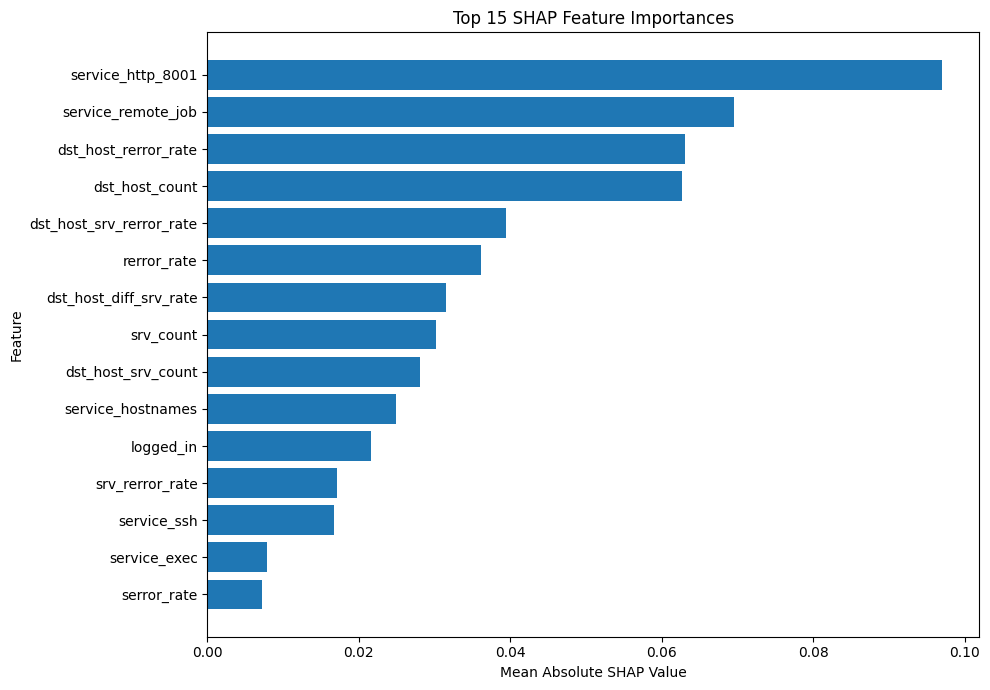

In [38]:
# ============================================================
# SHAP FEATURE IMPORTANCE BAR CHART
# ============================================================

# Select top 15 features
top_features = shap_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 SHAP Feature Importances")

plt.tight_layout()
plt.show()

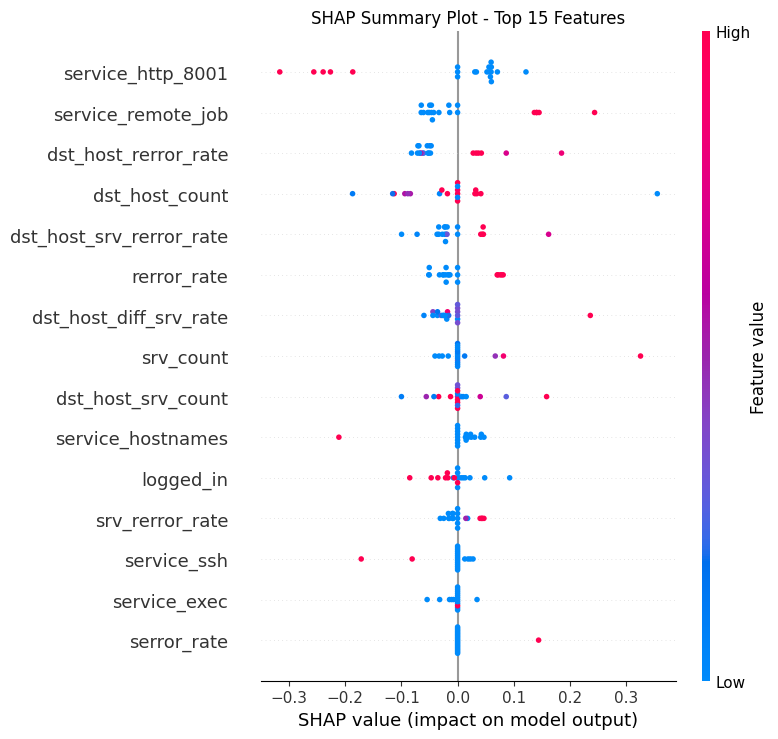

In [39]:
# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_array,
    X_shap_explain,
    feature_names=selected_feature_names,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Top 15 Features")
plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# SAVE SHAP RESULTS
# ============================================================

import os

# Create SHAP results folder
shap_results_path = project_path + "/shap_results"
os.makedirs(shap_results_path, exist_ok=True)

# Save feature importance table
shap_csv_file = shap_results_path + "/shap_feature_importance.csv"

shap_importance_df.to_csv(
    shap_csv_file,
    index=False
)

print("SHAP feature importance saved:")
print(shap_csv_file)

# Save top 15 features separately
top15_csv_file = shap_results_path + "/top15_shap_features.csv"

shap_importance_df.head(15).to_csv(
    top15_csv_file,
    index=False
)

print("\nTop 15 SHAP features saved:")
print(top15_csv_file)

SHAP feature importance saved:
/content/drive/MyDrive/Enhanced_IDS_Project/shap_results/shap_feature_importance.csv

Top 15 SHAP features saved:
/content/drive/MyDrive/Enhanced_IDS_Project/shap_results/top15_shap_features.csv


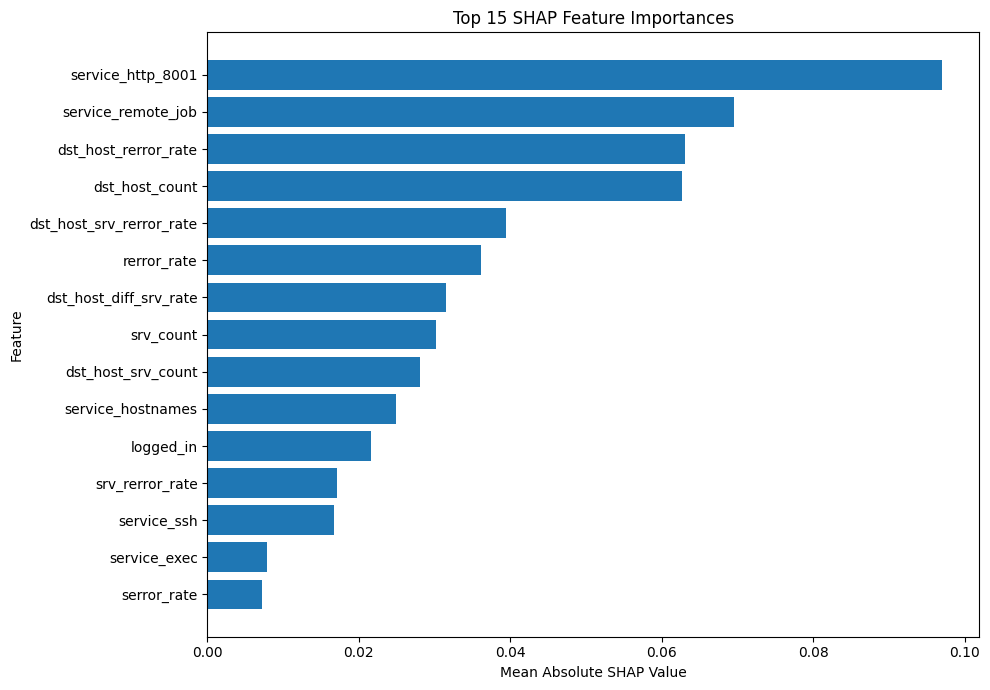

SHAP plot saved successfully:
/content/drive/MyDrive/Enhanced_IDS_Project/shap_results/shap_feature_importance.png


In [41]:
# ============================================================
# SAVE SHAP FEATURE IMPORTANCE PLOT
# ============================================================

shap_plot_file = shap_results_path + "/shap_feature_importance.png"

plt.figure(figsize=(10, 7))

top_features = shap_importance_df.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 15 SHAP Feature Importances")

plt.tight_layout()

plt.savefig(
    shap_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP plot saved successfully:")
print(shap_plot_file)

In [43]:
# ============================================================
# RELOAD MVO FITNESS FROM DRIVE
# ============================================================

best_fitness = float(
    np.load(project_path + "/mvo_results/best_fitness.npy")
)

print("MVO best fitness:", best_fitness)

MVO best fitness: 0.05539918032786882


/tmp/ipykernel_1995/2607589304.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  best_fitness = float(


In [44]:
# ============================================================
# RELOAD SAVED PROJECT RESULTS
# ============================================================

import numpy as np
import json

# ---------- MVO ----------
best_fitness = float(
    np.load(project_path + "/mvo_results/best_fitness.npy")
)

selected_feature_indices = np.load(
    project_path + "/mvo_results/selected_feature_indices.npy"
)

# ---------- ALO ----------
best_learning_rate = float(
    np.load(project_path + "/alo_results/best_learning_rate.npy")
)

best_gru_units = int(
    np.load(project_path + "/alo_results/best_gru_units.npy")
)

best_dropout = float(
    np.load(project_path + "/alo_results/best_dropout.npy")
)

best_alo_fitness = float(
    np.load(project_path + "/alo_results/best_fitness.npy")
)

# ---------- Final model results ----------
results_file = project_path + "/models/final_model_results.json"

with open(results_file, "r") as f:
    final_results = json.load(f)

# ---------- Confusion matrix ----------
confusion_matrix = np.load(
    project_path + "/models/final_confusion_matrix.npy"
)

test_loss = float(final_results["test_loss"])
test_accuracy = float(final_results["test_accuracy"])

print("All saved results loaded successfully!\n")

print("MVO selected features :", len(selected_feature_indices))
print("MVO fitness           :", best_fitness)

print("\nALO parameters")
print("Learning rate         :", best_learning_rate)
print("GRU units             :", best_gru_units)
print("Dropout               :", best_dropout)
print("ALO fitness           :", best_alo_fitness)

print("\nFinal Model")
print("Test loss             :", test_loss)
print("Test accuracy         :", test_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix)

All saved results loaded successfully!

MVO selected features : 33
MVO fitness           : 0.05539918032786882

ALO parameters
Learning rate         : 0.007316
GRU units             : 106
Dropout               : 0.265
ALO fitness           : 0.06016443

Final Model
Test loss             : 0.5604459047317505
Test accuracy         : 0.8234485387802124

Confusion Matrix:
[[9017  693]
 [3287 9546]]


/tmp/ipykernel_1995/460175084.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  best_fitness = float(


In [45]:
# ============================================================
# FINAL PROJECT RESULTS TABLE
# ============================================================

import pandas as pd

results_table = pd.DataFrame({
    "Stage": [
        "Original Features",
        "MVO Selected Features",
        "MVO Fitness",
        "ALO Learning Rate",
        "ALO GRU Units",
        "ALO Dropout",
        "Final Test Loss",
        "Final Test Accuracy"
    ],

    "Result": [
        122,
        len(selected_feature_indices),
        best_fitness,
        best_learning_rate,
        best_gru_units,
        best_dropout,
        test_loss,
        test_accuracy
    ]
})

print(results_table.to_string(index=False))

                Stage     Result
    Original Features 122.000000
MVO Selected Features  33.000000
          MVO Fitness   0.055399
    ALO Learning Rate   0.007316
        ALO GRU Units 106.000000
          ALO Dropout   0.265000
      Final Test Loss   0.560446
  Final Test Accuracy   0.823449


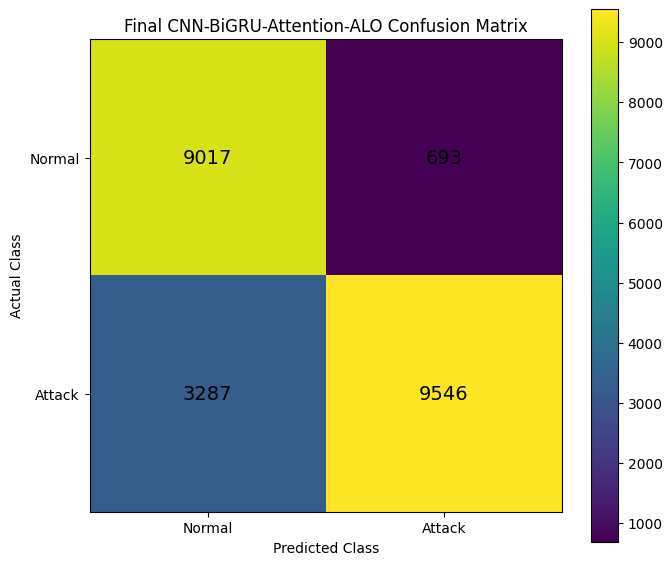

In [46]:
# ============================================================
# FINAL CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.imshow(confusion_matrix)

plt.title("Final CNN-BiGRU-Attention-ALO Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Normal", "Attack"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Attack"]
)

# Display values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            confusion_matrix[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [47]:
# ============================================================
# FINAL CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

# Generate predictions from final model
y_pred_probability = final_model.predict(
    X_test_cnn,
    verbose=0
)

y_pred = (y_pred_probability >= 0.5).astype(int).flatten()

# Classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    digits=4
)

print("FINAL CLASSIFICATION REPORT")
print("============================")
print(report)

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.7329    0.9286    0.8192      9710
      Attack     0.9323    0.7439    0.8275     12833

    accuracy                         0.8234     22543
   macro avg     0.8326    0.8362    0.8234     22543
weighted avg     0.8464    0.8234    0.8239     22543



In [48]:
# ============================================================
# SAVE FINAL CLASSIFICATION REPORT
# ============================================================

report_file = project_path + "/models/final_classification_report.txt"

with open(report_file, "w") as f:
    f.write("FINAL CNN-BiGRU-ATTENTION-ALO CLASSIFICATION REPORT\n")
    f.write("=" * 55 + "\n\n")
    f.write(report)

print("Classification report saved successfully!")
print(report_file)

Classification report saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_classification_report.txt


In [49]:
# ============================================================
# FINAL MODEL ARCHITECTURE
# ============================================================

print("FINAL CNN-BiGRU-ATTENTION-ALO MODEL")
print("=" * 50)

final_model.summary()

FINAL CNN-BiGRU-ATTENTION-ALO MODEL


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 33, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 33, 64)    │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 16, 64)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 16, 212)   │    109,392 │ max_pooling1d[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 16, 212)   │          0 │ bidirectional[0]… │
│ (Attention)         │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 212)       │          0 │ attention[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 212)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        213 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 329,585 (1.26 MB)

 Trainable params: 109,861 (429.14 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 219,724 (858.30 KB)

In [50]:
# ============================================================
# SAVE FINAL MODEL ARCHITECTURE
# ============================================================

from tensorflow.keras.utils import plot_model

architecture_file = project_path + "/models/final_model_architecture.png"

plot_model(
    final_model,
    to_file=architecture_file,
    show_shapes=True,
    show_layer_names=True,
    dpi=200
)

print("Model architecture saved successfully!")
print(architecture_file)

Model architecture saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_model_architecture.png


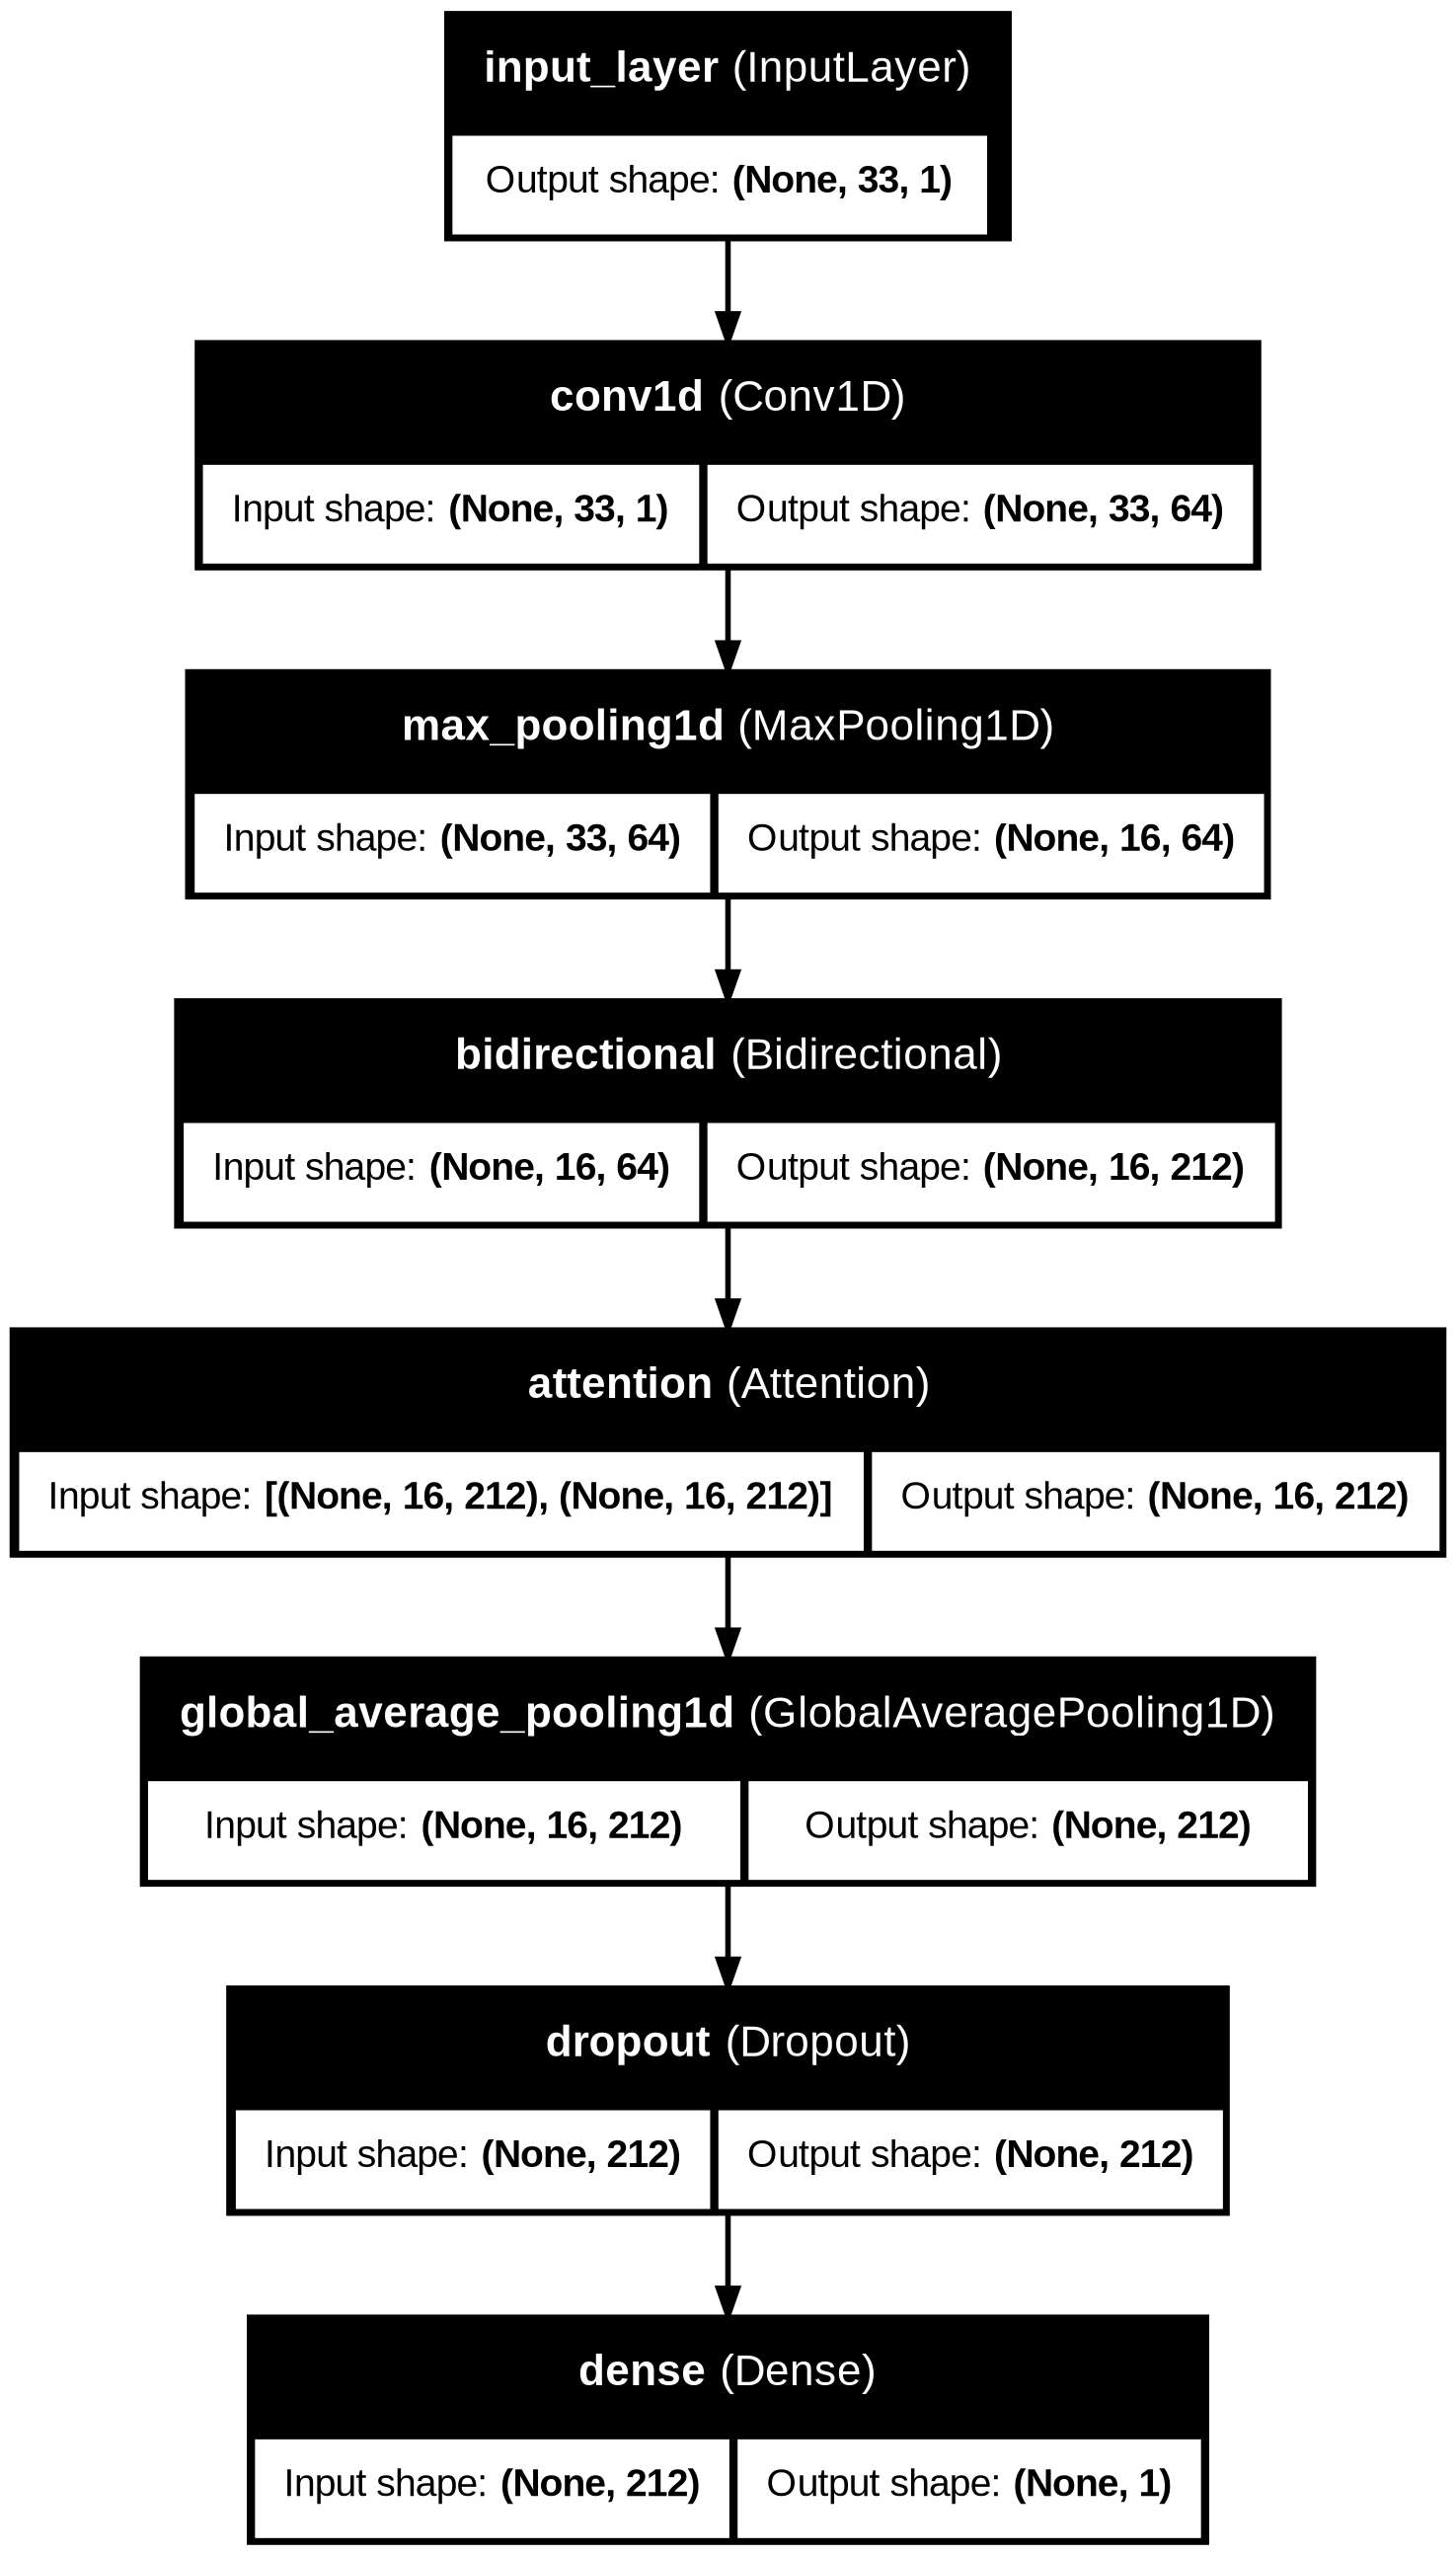

In [51]:
# ============================================================
# DISPLAY FINAL MODEL ARCHITECTURE
# ============================================================

from IPython.display import Image, display

display(
    Image(
        filename=project_path + "/models/final_model_architecture.png"
    )
)

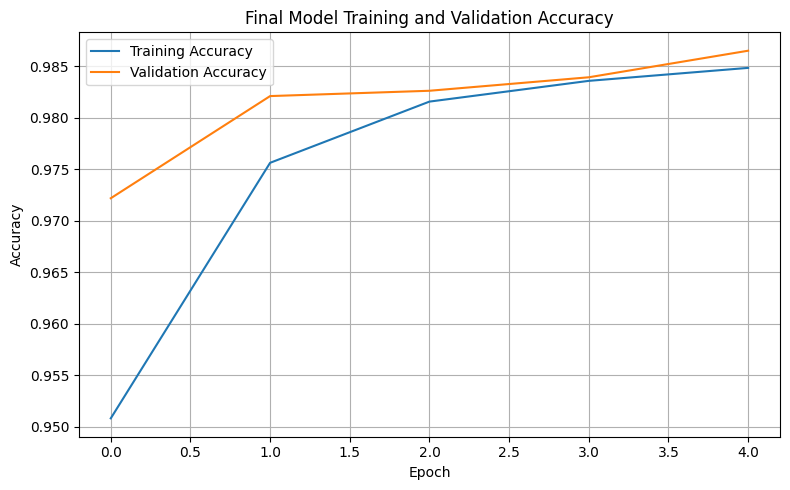

In [52]:
# ============================================================
# FINAL TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    final_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Final Model Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

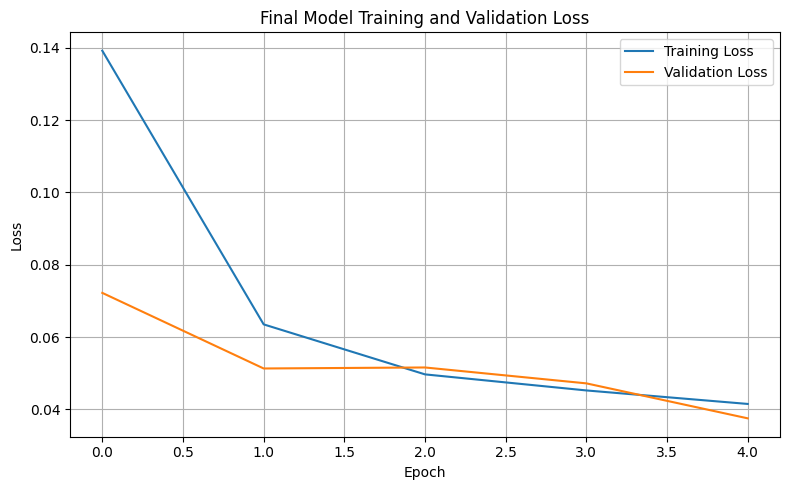

In [53]:
# ============================================================
# FINAL TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    final_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Final Model Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

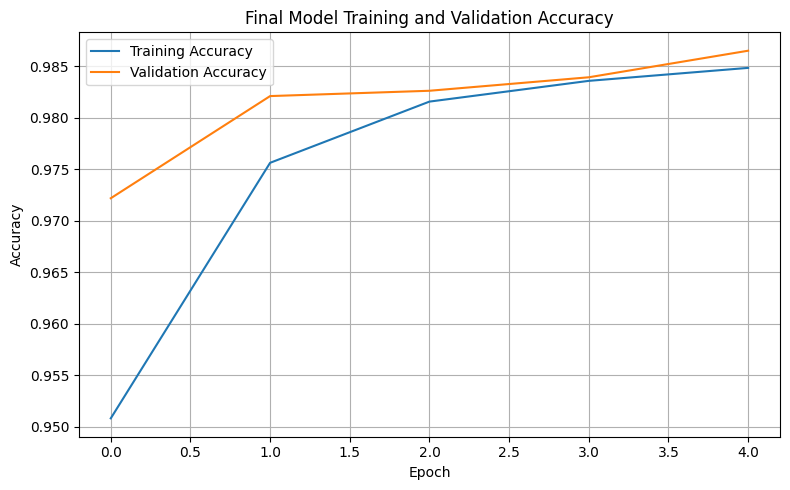

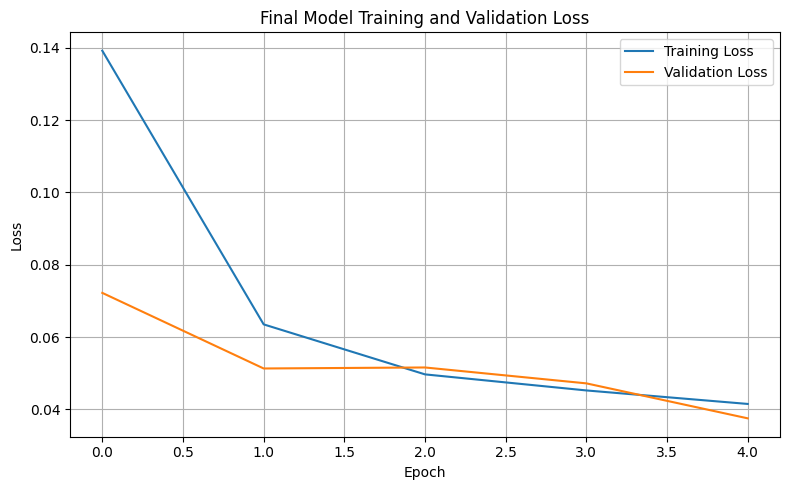

Graphs saved successfully!

Accuracy graph:
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_training_validation_accuracy.png

Loss graph:
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_training_validation_loss.png


In [54]:
# ============================================================
# SAVE FINAL TRAINING GRAPHS
# ============================================================

# ---------- Accuracy Graph ----------
accuracy_file = project_path + "/models/final_training_validation_accuracy.png"

plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    final_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Final Model Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    accuracy_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------- Loss Graph ----------
loss_file = project_path + "/models/final_training_validation_loss.png"

plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    final_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Final Model Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    loss_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("Graphs saved successfully!")
print("\nAccuracy graph:")
print(accuracy_file)

print("\nLoss graph:")
print(loss_file)

In [55]:
# ============================================================
# FINAL PROJECT SUMMARY
# ============================================================

print("=" * 65)
print("        ENHANCED INTRUSION DETECTION SYSTEM")
print("=" * 65)

print("\n1. DATASET")
print("   Dataset              : NSL-KDD")
print("   Classification       : Binary")
print("   Normal               : 0")
print("   Attack               : 1")

print("\n2. PREPROCESSING")
print("   Original features    : 122")
print("   Normalization        : Mean Normalization")

print("\n3. MVO FEATURE SELECTION")
print("   Selected features    :", len(selected_feature_indices))
print("   MVO fitness          :", best_fitness)

print("\n4. CNN-BiGRU-ATTENTION")
print("   CNN filters          : 64")
print("   CNN kernel size      : 3")
print("   BiGRU units          :", best_gru_units)
print("   Attention            : Self-Attention")

print("\n5. ALO HYPERPARAMETER TUNING")
print("   Learning rate        :", best_learning_rate)
print("   GRU units            :", best_gru_units)
print("   Dropout              :", best_dropout)

print("\n6. FINAL MODEL PERFORMANCE")
print("   Test Loss            :", test_loss)
print("   Test Accuracy        :", test_accuracy)

print("\n7. SHAP EXPLAINABILITY")
print("   Samples explained    :", len(X_shap_explain))
print("   Features explained   :", len(selected_feature_names))

print("\n8. FINAL ARCHITECTURE")
print("   Input → CNN → BiGRU → Attention")
print("        → Global Average Pooling")
print("        → Dropout → Sigmoid")
print("        → Normal / Attack")

print("\n" + "=" * 65)
print("              PROJECT PIPELINE COMPLETED")
print("=" * 65)

        ENHANCED INTRUSION DETECTION SYSTEM

1. DATASET
   Dataset              : NSL-KDD
   Classification       : Binary
   Normal               : 0
   Attack               : 1

2. PREPROCESSING
   Original features    : 122
   Normalization        : Mean Normalization

3. MVO FEATURE SELECTION
   Selected features    : 33
   MVO fitness          : 0.05539918032786882

4. CNN-BiGRU-ATTENTION
   CNN filters          : 64
   CNN kernel size      : 3
   BiGRU units          : 106
   Attention            : Self-Attention

5. ALO HYPERPARAMETER TUNING
   Learning rate        : 0.007316
   GRU units            : 106
   Dropout              : 0.265

6. FINAL MODEL PERFORMANCE
   Test Loss            : 0.5604459047317505
   Test Accuracy        : 0.8234485387802124

7. SHAP EXPLAINABILITY
   Samples explained    : 20
   Features explained   : 33

8. FINAL ARCHITECTURE
   Input → CNN → BiGRU → Attention
        → Global Average Pooling
        → Dropout → Sigmoid
        → Normal / Attack

  

In [56]:
# ============================================================
# SAVE FINAL PROJECT SUMMARY
# ============================================================

summary_file = project_path + "/models/final_project_summary.txt"

with open(summary_file, "w") as f:

    f.write("ENHANCED INTRUSION DETECTION SYSTEM\n")
    f.write("=" * 60 + "\n\n")

    f.write("DATASET\n")
    f.write("Dataset: NSL-KDD\n")
    f.write("Classification: Binary Classification\n")
    f.write("Normal: 0\n")
    f.write("Attack: 1\n\n")

    f.write("PREPROCESSING\n")
    f.write("Original features: 122\n")
    f.write("Normalization: Mean Normalization\n\n")

    f.write("MVO FEATURE SELECTION\n")
    f.write(f"Selected features: {len(selected_feature_indices)}\n")
    f.write(f"MVO fitness: {best_fitness}\n\n")

    f.write("CNN-BiGRU-ATTENTION\n")
    f.write("CNN filters: 64\n")
    f.write("CNN kernel size: 3\n")
    f.write(f"BiGRU units: {best_gru_units}\n")
    f.write("Attention: Self-Attention\n\n")

    f.write("ALO HYPERPARAMETER TUNING\n")
    f.write(f"Learning rate: {best_learning_rate}\n")
    f.write(f"GRU units: {best_gru_units}\n")
    f.write(f"Dropout: {best_dropout}\n\n")

    f.write("FINAL MODEL PERFORMANCE\n")
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n\n")

    f.write("SHAP EXPLAINABILITY\n")
    f.write(f"Samples explained: {len(X_shap_explain)}\n")
    f.write(f"Features explained: {len(selected_feature_names)}\n\n")

    f.write("ARCHITECTURE\n")
    f.write("Input → CNN → BiGRU → Attention → Global Average Pooling ")
    f.write("→ Dropout → Sigmoid → Normal/Attack\n")

print("Final project summary saved successfully!")
print(summary_file)

Final project summary saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_project_summary.txt


In [57]:
# ============================================================
# CHECK PROJECT FILES
# ============================================================

import os

folders = [
    "processed_data",
    "mvo_results",
    "models",
    "alo_results",
    "shap_results"
]

print("PROJECT FILE CHECK")
print("=" * 60)

for folder in folders:

    folder_path = project_path + "/" + folder

    print(f"\n📁 {folder}/")

    if os.path.exists(folder_path):

        files = os.listdir(folder_path)

        for file in files:
            print("   ✓", file)

    else:
        print("   Folder not found!")

print("\n" + "=" * 60)
print("FILE CHECK COMPLETED")

PROJECT FILE CHECK

📁 processed_data/
   ✓ X_train_normalized.npy
   ✓ X_test_normalized.npy
   ✓ y_train.npy
   ✓ y_test.npy
   ✓ encoder.pkl
   ✓ train_mean.npy
   ✓ train_range.npy

📁 mvo_results/
   ✓ selected_feature_indices.npy
   ✓ best_feature_mask.npy
   ✓ best_fitness.npy

📁 models/
   ✓ cnn_bigru_attention_initial.keras
   ✓ final_cnn_bigru_attention_alo.keras
   ✓ final_model_results.json
   ✓ final_confusion_matrix.npy
   ✓ final_classification_report.txt
   ✓ final_model_architecture.png
   ✓ final_training_validation_accuracy.png
   ✓ final_training_validation_loss.png
   ✓ final_project_summary.txt

📁 alo_results/
   ✓ best_learning_rate.npy
   ✓ best_gru_units.npy
   ✓ best_dropout.npy
   ✓ best_fitness.npy

📁 shap_results/
   ✓ shap_feature_importance.csv
   ✓ top15_shap_features.csv
   ✓ shap_feature_importance.png

FILE CHECK COMPLETED


In [58]:
# ============================================================
# TOP 10 SHAP FEATURES
# ============================================================

print("=" * 60)
print("TOP 10 FEATURES FROM SHAP")
print("=" * 60)

top_10_shap = shap_importance_df.head(10)

for i, row in enumerate(top_10_shap.itertuples(index=False), start=1):
    print(
        f"{i}. {row.Feature}  →  "
        f"Importance = {row.Importance:.6f}"
    )

TOP 10 FEATURES FROM SHAP
1. service_http_8001  →  Importance = 0.097033
2. service_remote_job  →  Importance = 0.069584
3. dst_host_rerror_rate  →  Importance = 0.063103
4. dst_host_count  →  Importance = 0.062627
5. dst_host_srv_rerror_rate  →  Importance = 0.039382
6. rerror_rate  →  Importance = 0.036076
7. dst_host_diff_srv_rate  →  Importance = 0.031494
8. srv_count  →  Importance = 0.030163
9. dst_host_srv_count  →  Importance = 0.028063
10. service_hostnames  →  Importance = 0.024932


In [59]:
# ============================================================
# SAVE TOP 10 SHAP FEATURES
# ============================================================

top_shap_file = project_path + "/shap_results/top10_shap_features.txt"

with open(top_shap_file, "w") as f:

    f.write("TOP 10 SHAP FEATURES\n")
    f.write("=" * 50 + "\n\n")

    for i, row in enumerate(
        shap_importance_df.head(10).itertuples(index=False),
        start=1
    ):
        f.write(
            f"{i}. {row.Feature} - "
            f"Importance: {row.Importance:.6f}\n"
        )

print("Top 10 SHAP features saved successfully!")
print(top_shap_file)

Top 10 SHAP features saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/shap_results/top10_shap_features.txt


In [60]:
# ============================================================
# FINAL MODEL PREDICTION TEST
# ============================================================

# Select 10 unseen test samples
sample_indices = np.arange(10)

sample_X = X_test_cnn[sample_indices]
sample_y = y_test[sample_indices]

# Predict
sample_probabilities = final_model.predict(
    sample_X,
    verbose=0
).flatten()

sample_predictions = (
    sample_probabilities >= 0.5
).astype(int)

print("=" * 60)
print("FINAL MODEL PREDICTION TEST")
print("=" * 60)

for i in range(10):

    actual = "Attack" if sample_y[i] == 1 else "Normal"
    predicted = "Attack" if sample_predictions[i] == 1 else "Normal"

    print(
        f"Sample {i+1}: "
        f"Actual = {actual}, "
        f"Predicted = {predicted}, "
        f"Confidence = {sample_probabilities[i]:.4f}"
    )

FINAL MODEL PREDICTION TEST
Sample 1: Actual = Attack, Predicted = Attack, Confidence = 1.0000
Sample 2: Actual = Attack, Predicted = Attack, Confidence = 1.0000
Sample 3: Actual = Normal, Predicted = Normal, Confidence = 0.0124
Sample 4: Actual = Attack, Predicted = Attack, Confidence = 0.9977
Sample 5: Actual = Attack, Predicted = Attack, Confidence = 0.9970
Sample 6: Actual = Normal, Predicted = Normal, Confidence = 0.0001
Sample 7: Actual = Normal, Predicted = Attack, Confidence = 0.5893
Sample 8: Actual = Attack, Predicted = Attack, Confidence = 0.6852
Sample 9: Actual = Normal, Predicted = Normal, Confidence = 0.0000
Sample 10: Actual = Attack, Predicted = Normal, Confidence = 0.0290


In [61]:
# ============================================================
# FINAL EVALUATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("=" * 50)
print("FINAL MODEL METRICS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

FINAL MODEL METRICS
Accuracy  : 0.8234
Precision : 0.9323
Recall    : 0.7439
F1-Score  : 0.8275


In [62]:
# ============================================================
# SAVE FINAL EVALUATION METRICS
# ============================================================

metrics_file = project_path + "/models/final_metrics.json"

final_metrics = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open(metrics_file, "w") as f:
    json.dump(final_metrics, f, indent=4)

print("Final metrics saved successfully!")
print(metrics_file)

print("\nFinal Metrics")
print("-------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Final metrics saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_metrics.json

Final Metrics
-------------
Accuracy  : 0.8234
Precision : 0.9323
Recall    : 0.7439
F1-Score  : 0.8275


In [63]:
# ============================================================
# CHECK FINAL MODEL FILE
# ============================================================

import os

final_model_path = project_path + "/models/final_cnn_bigru_attention_alo.keras"

if os.path.exists(final_model_path):

    file_size_mb = os.path.getsize(final_model_path) / (1024 * 1024)

    print("=" * 55)
    print("FINAL MODEL VERIFIED")
    print("=" * 55)

    print("Model file:")
    print(final_model_path)

    print(f"\nModel size: {file_size_mb:.2f} MB")

else:

    print("Final model file was NOT found!")
    print(final_model_path)

FINAL MODEL VERIFIED
Model file:
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_cnn_bigru_attention_alo.keras

Model size: 1.31 MB


In [64]:
# ============================================================
# RELOAD AND TEST SAVED FINAL MODEL
# ============================================================

from tensorflow.keras.models import load_model

# Load saved model
verified_model = load_model(final_model_path)

print("Saved model loaded successfully!\n")

# Predict on test data
verified_probabilities = verified_model.predict(
    X_test_cnn,
    verbose=0
).flatten()

verified_predictions = (
    verified_probabilities >= 0.5
).astype(int)

# Calculate accuracy
verified_accuracy = accuracy_score(
    y_test,
    verified_predictions
)

print("Verification Accuracy:", f"{verified_accuracy:.4f}")
print("Verification Accuracy (%):", f"{verified_accuracy * 100:.2f}%")

Saved model loaded successfully!

Verification Accuracy: 0.8234
Verification Accuracy (%): 82.34%


In [65]:
# ============================================================
# SINGLE FINAL RESULTS REPORT
# ============================================================

final_report = f"""
============================================================
       ENHANCED INTRUSION DETECTION SYSTEM
============================================================

DATASET
------------------------------------------------------------
Dataset                 : NSL-KDD
Classification          : Binary
Normal                  : 0
Attack                  : 1

PREPROCESSING
------------------------------------------------------------
Original Features       : 122
MVO Selected Features   : {len(selected_feature_indices)}

MVO FEATURE SELECTION
------------------------------------------------------------
MVO Fitness             : {best_fitness:.6f}

CNN-BiGRU-ATTENTION
------------------------------------------------------------
CNN Filters             : 64
CNN Kernel Size         : 3
BiGRU Units             : {best_gru_units}
Attention               : Self-Attention
Pooling                 : Global Average Pooling

ALO HYPERPARAMETER TUNING
------------------------------------------------------------
Learning Rate           : {best_learning_rate}
GRU Units               : {best_gru_units}
Dropout                 : {best_dropout}
ALO Fitness             : {best_alo_fitness:.6f}

FINAL MODEL
------------------------------------------------------------
Test Loss               : {test_loss:.6f}
Test Accuracy           : {test_accuracy:.6f}
Test Accuracy (%)       : {test_accuracy * 100:.2f}%

EVALUATION METRICS
------------------------------------------------------------
Accuracy                : {accuracy:.6f}
Precision               : {precision:.6f}
Recall                  : {recall:.6f}
F1-Score                : {f1:.6f}

CONFUSION MATRIX
------------------------------------------------------------
                         Predicted
                     Normal    Attack
Actual Normal       {confusion_matrix[0][0]:6d}    {confusion_matrix[0][1]:6d}
Actual Attack       {confusion_matrix[1][0]:6d}    {confusion_matrix[1][1]:6d}

SHAP EXPLAINABILITY
------------------------------------------------------------
Samples Explained      : {len(X_shap_explain)}
Features Explained     : {len(selected_feature_names)}

MODEL PIPELINE
------------------------------------------------------------
NSL-KDD Dataset
      |
      v
Preprocessing
      |
      v
Mean Normalization
      |
      v
MVO Feature Selection
      |
      v
33 Selected Features
      |
      v
CNN
      |
      v
BiGRU
      |
      v
Attention
      |
      v
Global Average Pooling
      |
      v
Dropout
      |
      v
Sigmoid Output
      |
      v
Normal / Attack
      |
      v
SHAP Explainability

============================================================
                 END OF RESULTS
============================================================
"""

print(final_report)


       ENHANCED INTRUSION DETECTION SYSTEM

DATASET
------------------------------------------------------------
Dataset                 : NSL-KDD
Classification          : Binary
Normal                  : 0
Attack                  : 1

PREPROCESSING
------------------------------------------------------------
Original Features       : 122
MVO Selected Features   : 33

MVO FEATURE SELECTION
------------------------------------------------------------
MVO Fitness             : 0.055399

CNN-BiGRU-ATTENTION
------------------------------------------------------------
CNN Filters             : 64
CNN Kernel Size         : 3
BiGRU Units             : 106
Attention               : Self-Attention
Pooling                 : Global Average Pooling

ALO HYPERPARAMETER TUNING
------------------------------------------------------------
Learning Rate           : 0.007316
GRU Units               : 106
Dropout                 : 0.265
ALO Fitness             : 0.060164

FINAL MODEL
-----------------

In [66]:
# ============================================================
# SAVE COMPLETE FINAL REPORT
# ============================================================

complete_report_file = (
    project_path + "/models/COMPLETE_FINAL_RESULTS_REPORT.txt"
)

with open(complete_report_file, "w") as f:
    f.write(final_report)

print("Complete final report saved successfully!")
print(complete_report_file)

Complete final report saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/COMPLETE_FINAL_RESULTS_REPORT.txt


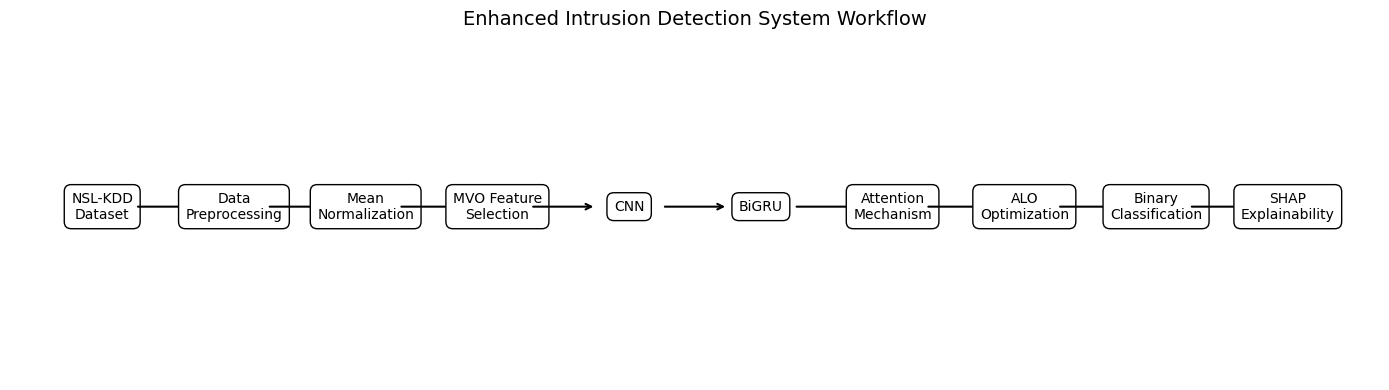

Workflow diagram saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/project_workflow_diagram.png


In [67]:
# ============================================================
# PROJECT WORKFLOW DIAGRAM
# ============================================================

import matplotlib.pyplot as plt

steps = [
    "NSL-KDD\nDataset",
    "Data\nPreprocessing",
    "Mean\nNormalization",
    "MVO Feature\nSelection",
    "CNN",
    "BiGRU",
    "Attention\nMechanism",
    "ALO\nOptimization",
    "Binary\nClassification",
    "SHAP\nExplainability"
]

fig, ax = plt.subplots(figsize=(14, 4))

ax.axis("off")

for i, step in enumerate(steps):
    ax.text(
        i,
        0.5,
        step,
        ha="center",
        va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.5",
            edgecolor="black",
            facecolor="white"
        )
    )

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(i + 0.75, 0.5),
            xytext=(i + 0.25, 0.5),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_xlim(-0.7, len(steps) - 0.3)
ax.set_ylim(0, 1)

plt.title(
    "Enhanced Intrusion Detection System Workflow",
    fontsize=14
)

plt.tight_layout()

workflow_file = (
    project_path + "/models/project_workflow_diagram.png"
)

plt.savefig(
    workflow_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Workflow diagram saved successfully!")
print(workflow_file)

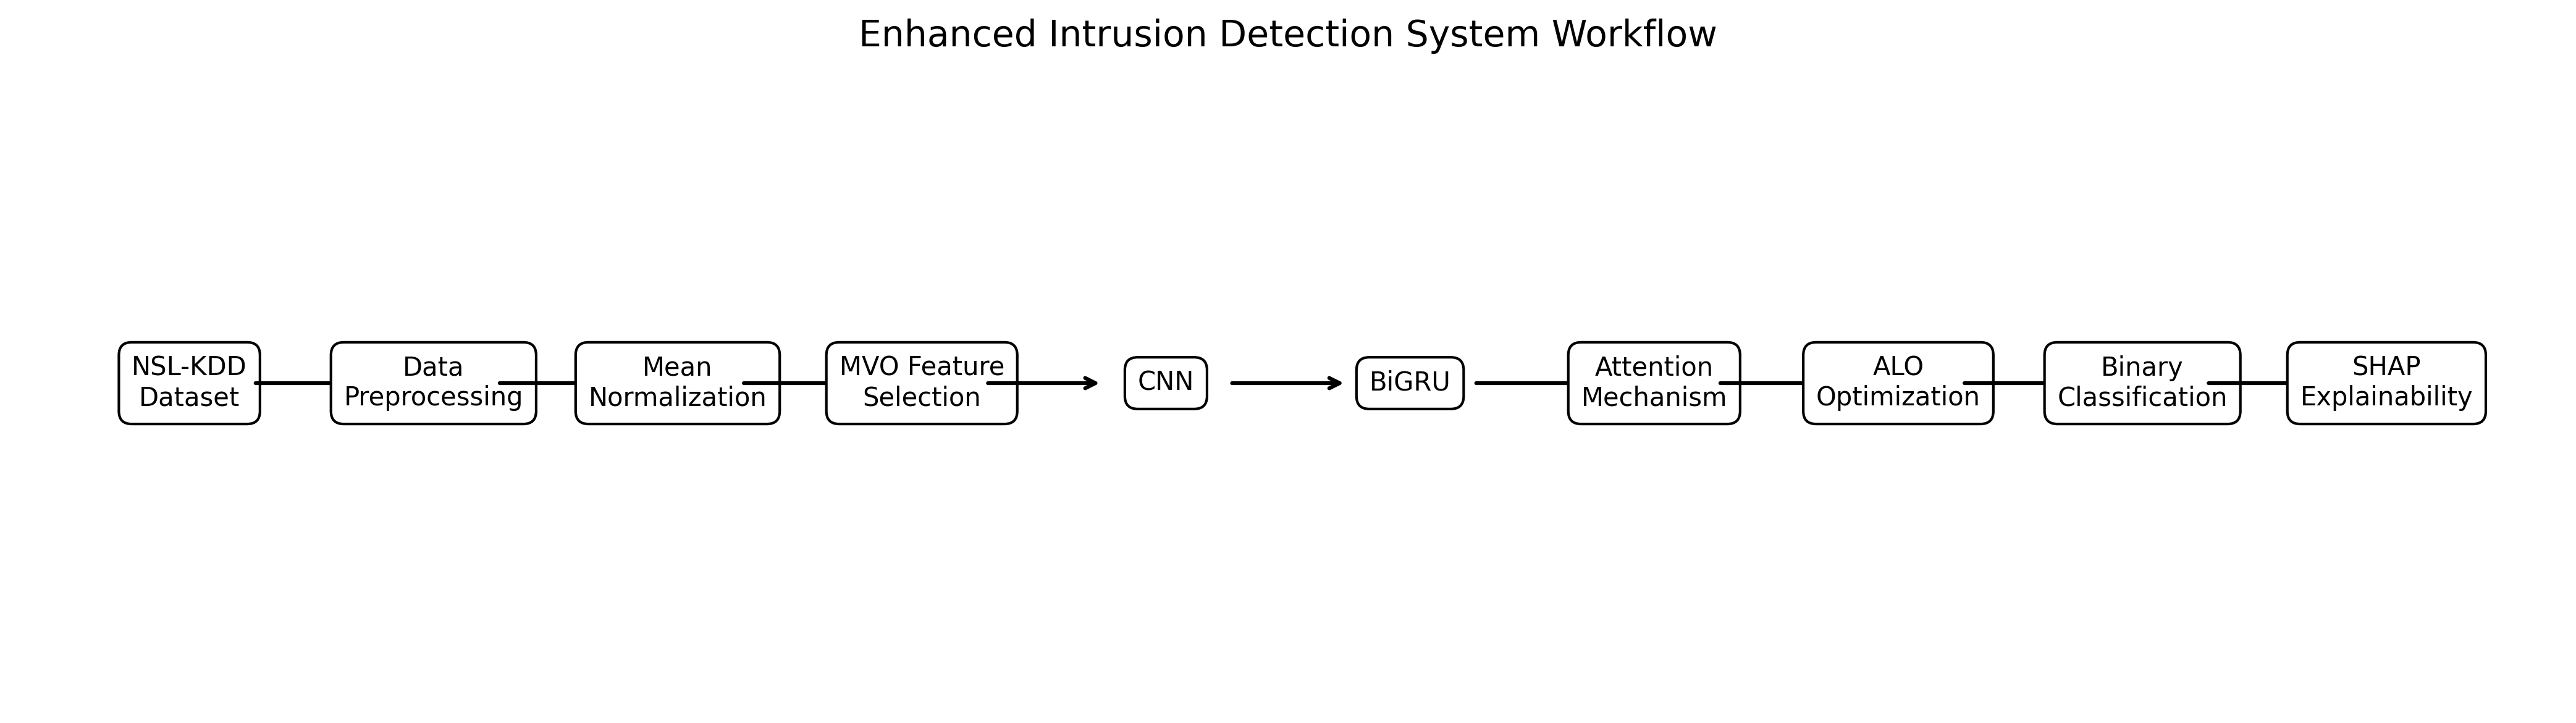

In [68]:
# ============================================================
# DISPLAY PROJECT WORKFLOW
# ============================================================

from IPython.display import Image, display

display(
    Image(
        filename=project_path + "/models/project_workflow_diagram.png"
    )
)

In [69]:
# ============================================================
# ARCHITECTURE EXPLANATION
# ============================================================

architecture_explanation = """
ENHANCED INTRUSION DETECTION SYSTEM
ARCHITECTURE EXPLANATION
===================================

1. DATASET
-----------
NSL-KDD is used as the network intrusion detection dataset.

The data contains network connection information and a label
indicating whether the connection is Normal or an Attack.

Classification:
0 = Normal
1 = Attack


2. DATA PREPROCESSING
---------------------
Categorical network features are converted into numerical
values using One-Hot Encoding.

The processed features are then mean-normalized.

Original processed feature count:
122


3. MVO FEATURE SELECTION
------------------------
Multi-Verse Optimizer (MVO) is used to select the most useful
features.

It reduces the feature space:

122 Features
      ↓
33 Selected Features

This helps reduce unnecessary information before classification.


4. CNN
-------
The Convolutional Neural Network extracts local patterns from
the selected network features.

CNN used:
64 filters
Kernel size = 3


5. BiGRU
--------
Bidirectional GRU processes the feature sequence in both
forward and backward directions.

This helps the model learn relationships between different
parts of the network traffic.

Final tuned GRU units:
106


6. ATTENTION MECHANISM
----------------------
The Attention mechanism gives more importance to important
parts of the learned feature sequence.

It helps the model focus on features that are more relevant
for classification.


7. GLOBAL AVERAGE POOLING
-------------------------
The learned sequence representation is converted into a
compact representation before classification.


8. DROPOUT
----------
Dropout is used to reduce overfitting.

Final tuned dropout:
0.265


9. ALO HYPERPARAMETER OPTIMIZATION
----------------------------------
Ant Lion Optimizer (ALO) is used to search for suitable
hyperparameters.

Parameters optimized:
- Learning rate
- GRU units
- Dropout

Final learning rate:
0.007316

Final GRU units:
106

Final dropout:
0.265


10. BINARY CLASSIFICATION
-------------------------
A sigmoid output layer produces the final prediction.

Output:
0 = Normal
1 = Attack


11. SHAP EXPLAINABILITY
----------------------
SHAP explains which features influenced the model prediction.

It calculates the contribution of individual features and
produces feature importance values.

This makes the IDS model more interpretable.


COMPLETE ARCHITECTURE
---------------------

NSL-KDD
   ↓
Preprocessing
   ↓
Mean Normalization
   ↓
MVO Feature Selection
   ↓
33 Selected Features
   ↓
CNN
   ↓
BiGRU
   ↓
Attention
   ↓
Global Average Pooling
   ↓
Dropout
   ↓
Sigmoid
   ↓
Normal / Attack
   ↓
SHAP Explainability
"""

architecture_file = (
    project_path + "/models/architecture_explanation.txt"
)

with open(architecture_file, "w") as f:
    f.write(architecture_explanation)

print(architecture_explanation)

print("\nArchitecture explanation saved successfully!")
print(architecture_file)


ENHANCED INTRUSION DETECTION SYSTEM
ARCHITECTURE EXPLANATION

1. DATASET
-----------
NSL-KDD is used as the network intrusion detection dataset.

The data contains network connection information and a label
indicating whether the connection is Normal or an Attack.

Classification:
0 = Normal
1 = Attack


2. DATA PREPROCESSING
---------------------
Categorical network features are converted into numerical
values using One-Hot Encoding.

The processed features are then mean-normalized.

Original processed feature count:
122


3. MVO FEATURE SELECTION
------------------------
Multi-Verse Optimizer (MVO) is used to select the most useful
features.

It reduces the feature space:

122 Features
      ↓
33 Selected Features

This helps reduce unnecessary information before classification.


4. CNN
-------
The Convolutional Neural Network extracts local patterns from
the selected network features.

CNN used:
64 filters
Kernel size = 3


5. BiGRU
--------
Bidirectional GRU processes the feature

In [70]:
# ============================================================
# FINAL PROJECT FOLDER STRUCTURE
# ============================================================

import os

def show_folder(path, indent=""):
    if not os.path.exists(path):
        return

    items = sorted(os.listdir(path))

    for item in items:
        item_path = os.path.join(path, item)

        if os.path.isdir(item_path):
            print(f"{indent}📁 {item}/")
            show_folder(item_path, indent + "    ")
        else:
            print(f"{indent}📄 {item}")

print("=" * 65)
print("       ENHANCED IDS PROJECT - FINAL FILE STRUCTURE")
print("=" * 65)

print("\n📁 Enhanced_IDS_Project/")
show_folder(project_path, "    ")

print("\n" + "=" * 65)
print("FILE STRUCTURE CHECK COMPLETED")
print("=" * 65)

       ENHANCED IDS PROJECT - FINAL FILE STRUCTURE

📁 Enhanced_IDS_Project/
    📁 alo_results/
        📄 best_dropout.npy
        📄 best_fitness.npy
        📄 best_gru_units.npy
        📄 best_learning_rate.npy
    📁 models/
        📄 COMPLETE_FINAL_RESULTS_REPORT.txt
        📄 architecture_explanation.txt
        📄 cnn_bigru_attention_initial.keras
        📄 final_classification_report.txt
        📄 final_cnn_bigru_attention_alo.keras
        📄 final_confusion_matrix.npy
        📄 final_metrics.json
        📄 final_model_architecture.png
        📄 final_model_results.json
        📄 final_project_summary.txt
        📄 final_training_validation_accuracy.png
        📄 final_training_validation_loss.png
        📄 project_workflow_diagram.png
    📁 mvo_results/
        📄 best_feature_mask.npy
        📄 best_fitness.npy
        📄 selected_feature_indices.npy
    📁 processed_data/
        📄 X_test_normalized.npy
        📄 X_train_normalized.npy
        📄 encoder.pkl
        📄 train_mean.npy


In [71]:
# ============================================================
# FINAL END-TO-END MODEL TEST
# ============================================================

import numpy as np
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score

# ------------------------------------------------------------
# 1. Load processed test data
# ------------------------------------------------------------

X_test_loaded = np.load(
    project_path + "/processed_data/X_test_normalized.npy"
)

y_test_loaded = np.load(
    project_path + "/processed_data/y_test.npy"
)

print("Loaded test data:")
print("X_test shape:", X_test_loaded.shape)
print("y_test shape:", y_test_loaded.shape)


# ------------------------------------------------------------
# 2. Load MVO selected feature indices
# ------------------------------------------------------------

selected_indices_loaded = np.load(
    project_path + "/mvo_results/selected_feature_indices.npy"
)

print("\nMVO selected features:", len(selected_indices_loaded))


# ------------------------------------------------------------
# 3. Select MVO features
# ------------------------------------------------------------

X_test_selected_loaded = X_test_loaded[
    :, selected_indices_loaded
]

print(
    "After MVO feature selection:",
    X_test_selected_loaded.shape
)


# ------------------------------------------------------------
# 4. Reshape for CNN
# ------------------------------------------------------------

X_test_cnn_loaded = X_test_selected_loaded.reshape(
    X_test_selected_loaded.shape[0],
    X_test_selected_loaded.shape[1],
    1
)

print(
    "CNN input shape:",
    X_test_cnn_loaded.shape
)


# ------------------------------------------------------------
# 5. Load saved final model
# ------------------------------------------------------------

saved_final_model = load_model(
    project_path +
    "/models/final_cnn_bigru_attention_alo.keras"
)

print("\nSaved final model loaded successfully.")


# ------------------------------------------------------------
# 6. Predict
# ------------------------------------------------------------

predicted_probabilities = saved_final_model.predict(
    X_test_cnn_loaded,
    verbose=0
).flatten()

predicted_classes = (
    predicted_probabilities >= 0.5
).astype(int)


# ------------------------------------------------------------
# 7. Calculate accuracy
# ------------------------------------------------------------

end_to_end_accuracy = accuracy_score(
    y_test_loaded,
    predicted_classes
)

print("\n" + "=" * 55)
print("END-TO-END TEST RESULT")
print("=" * 55)

print(
    f"Final Accuracy: "
    f"{end_to_end_accuracy * 100:.2f}%"
)

print("=" * 55)

Loaded test data:
X_test shape: (22543, 122)
y_test shape: (22543,)

MVO selected features: 33
After MVO feature selection: (22543, 33)
CNN input shape: (22543, 33, 1)

Saved final model loaded successfully.

END-TO-END TEST RESULT
Final Accuracy: 82.34%


In [72]:
# ============================================================
# MASTER PROJECT RESULTS
# ============================================================

import json

master_results = {
    "project": {
        "name": "Enhanced Intrusion Detection System",
        "dataset": "NSL-KDD",
        "classification": "Binary Classification",
        "classes": {
            "0": "Normal",
            "1": "Attack"
        }
    },

    "preprocessing": {
        "original_features": 122,
        "normalization": "Mean Normalization"
    },

    "mvo": {
        "selected_features": int(len(selected_feature_indices)),
        "fitness": float(best_fitness)
    },

    "cnn_bigru_attention": {
        "cnn_filters": 64,
        "kernel_size": 3,
        "gru_units": int(best_gru_units),
        "attention": True,
        "global_average_pooling": True
    },

    "alo": {
        "learning_rate": float(best_learning_rate),
        "gru_units": int(best_gru_units),
        "dropout": float(best_dropout),
        "fitness": float(best_alo_fitness)
    },

    "performance": {
        "test_loss": float(test_loss),
        "test_accuracy": float(test_accuracy),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1)
    },

    "confusion_matrix": confusion_matrix.tolist(),

    "shap": {
        "samples_explained": int(len(X_shap_explain)),
        "features_explained": int(len(selected_feature_names)),
        "top_features": shap_importance_df.head(10)["Feature"].tolist()
    }
}

master_results_file = (
    project_path + "/models/MASTER_PROJECT_RESULTS.json"
)

with open(master_results_file, "w") as f:
    json.dump(master_results, f, indent=4)

print("MASTER PROJECT RESULTS SAVED")
print("=" * 55)
print(master_results_file)
print("=" * 55)

MASTER PROJECT RESULTS SAVED
/content/drive/MyDrive/Enhanced_IDS_Project/models/MASTER_PROJECT_RESULTS.json


In [73]:
# ============================================================
# CREATE PROJECT README
# ============================================================

readme = f"""
# Enhanced Intrusion Detection System

## 1. Project Overview

This project implements an enhanced Intrusion Detection System
using Machine Learning and Deep Learning techniques.

The implemented pipeline combines:

- Mean Normalization
- Multi-Verse Optimizer (MVO)
- CNN
- Bidirectional GRU (BiGRU)
- Attention Mechanism
- Ant Lion Optimizer (ALO)
- SHAP Explainable AI

## 2. Dataset

Dataset: NSL-KDD

Classification:
- 0 = Normal
- 1 = Attack

Original processed feature count: 122

## 3. Feature Selection

MVO was used for feature selection.

Original features: 122
Selected features: {len(selected_feature_indices)}

## 4. Deep Learning Model

Architecture:

Input
  ↓
CNN
  ↓
MaxPooling
  ↓
BiGRU
  ↓
Attention
  ↓
Global Average Pooling
  ↓
Dropout
  ↓
Sigmoid
  ↓
Normal / Attack

CNN filters: 64
CNN kernel size: 3
BiGRU units: {best_gru_units}

## 5. ALO Optimization

ALO was used to tune important hyperparameters.

Learning rate: {best_learning_rate}
GRU units: {best_gru_units}
Dropout: {best_dropout}

## 6. Final Performance

Test Loss: {test_loss:.6f}
Test Accuracy: {test_accuracy * 100:.2f}%

Accuracy: {accuracy:.6f}
Precision: {precision:.6f}
Recall: {recall:.6f}
F1-Score: {f1:.6f}

## 7. Explainable AI

SHAP was used to identify the contribution of selected
network features to model predictions.

## 8. Project Pipeline

NSL-KDD
  ↓
Preprocessing
  ↓
Mean Normalization
  ↓
MVO Feature Selection
  ↓
CNN-BiGRU-Attention
  ↓
ALO Hyperparameter Optimization
  ↓
Binary Classification
  ↓
SHAP Explainability

## 9. Main Output Folders

processed_data/
mvo_results/
alo_results/
shap_results/
models/

"""

readme_file = project_path + "/README.txt"

with open(readme_file, "w") as f:
    f.write(readme)

print("README created successfully!")
print(readme_file)

README created successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/README.txt


In [74]:
# ============================================================
# FINAL PROJECT CHECKLIST
# ============================================================

import os

required_files = {
    "Normalized Training Data":
        project_path + "/processed_data/X_train_normalized.npy",

    "Normalized Test Data":
        project_path + "/processed_data/X_test_normalized.npy",

    "Training Labels":
        project_path + "/processed_data/y_train.npy",

    "Test Labels":
        project_path + "/processed_data/y_test.npy",

    "MVO Selected Features":
        project_path + "/mvo_results/selected_feature_indices.npy",

    "MVO Fitness":
        project_path + "/mvo_results/best_fitness.npy",

    "ALO Learning Rate":
        project_path + "/alo_results/best_learning_rate.npy",

    "ALO GRU Units":
        project_path + "/alo_results/best_gru_units.npy",

    "ALO Dropout":
        project_path + "/alo_results/best_dropout.npy",

    "Final Model":
        project_path + "/models/final_cnn_bigru_attention_alo.keras",

    "Confusion Matrix":
        project_path + "/models/final_confusion_matrix.npy",

    "Classification Report":
        project_path + "/models/final_classification_report.txt",

    "Final Metrics":
        project_path + "/models/final_metrics.json",

    "Model Architecture":
        project_path + "/models/final_model_architecture.png",

    "Workflow Diagram":
        project_path + "/models/project_workflow_diagram.png",

    "SHAP Importance":
        project_path + "/shap_results/shap_feature_importance.csv",

    "SHAP Plot":
        project_path + "/shap_results/shap_feature_importance.png",

    "Master Results":
        project_path + "/models/MASTER_PROJECT_RESULTS.json"
}

print("=" * 70)
print("             FINAL PROJECT CHECKLIST")
print("=" * 70)

missing_files = []

for name, file_path in required_files.items():

    if os.path.exists(file_path):
        print(f"✓ {name}")
    else:
        print(f"✗ {name}  <-- MISSING")
        missing_files.append(name)

print("\n" + "=" * 70)

if len(missing_files) == 0:
    print("ALL IMPORTANT PROJECT FILES ARE PRESENT ✓")
else:
    print("MISSING FILES:")
    for file in missing_files:
        print(" -", file)

print("=" * 70)

             FINAL PROJECT CHECKLIST
✓ Normalized Training Data
✓ Normalized Test Data
✓ Training Labels
✓ Test Labels
✓ MVO Selected Features
✓ MVO Fitness
✓ ALO Learning Rate
✓ ALO GRU Units
✓ ALO Dropout
✓ Final Model
✓ Confusion Matrix
✓ Classification Report
✓ Final Metrics
✓ Model Architecture
✓ Workflow Diagram
✓ SHAP Importance
✓ SHAP Plot
✓ Master Results

ALL IMPORTANT PROJECT FILES ARE PRESENT ✓


In [75]:
# ============================================================
# FINAL RESULTS TABLE FOR REPORT / PPT
# ============================================================

import pandas as pd

final_results_table = pd.DataFrame({
    "Component": [
        "Dataset",
        "Classification",
        "Original Features",
        "MVO Selected Features",
        "MVO Fitness",
        "CNN Filters",
        "CNN Kernel Size",
        "BiGRU Units",
        "ALO Learning Rate",
        "ALO Dropout",
        "Test Loss",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Result": [
        "NSL-KDD",
        "Binary",
        122,
        len(selected_feature_indices),
        round(best_fitness, 6),
        64,
        3,
        best_gru_units,
        best_learning_rate,
        best_dropout,
        round(test_loss, 6),
        f"{test_accuracy * 100:.2f}%",
        f"{precision:.4f}",
        f"{recall:.4f}",
        f"{f1:.4f}"
    ]
})

print("=" * 65)
print("FINAL RESULTS TABLE")
print("=" * 65)

display(final_results_table)

FINAL RESULTS TABLE


,Component,Result
0,Dataset,NSL-KDD
1,Classification,Binary
2,Original Features,122
3,MVO Selected Features,33
4,MVO Fitness,0.055399
5,CNN Filters,64
6,CNN Kernel Size,3
7,BiGRU Units,106
8,ALO Learning Rate,0.007316
9,ALO Dropout,0.265


In [76]:
# ============================================================
# SAVE FINAL RESULTS TABLE
# ============================================================

results_table_file = (
    project_path + "/models/final_results_table.csv"
)

final_results_table.to_csv(
    results_table_file,
    index=False
)

print("Final results table saved successfully!")
print(results_table_file)

Final results table saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_results_table.csv


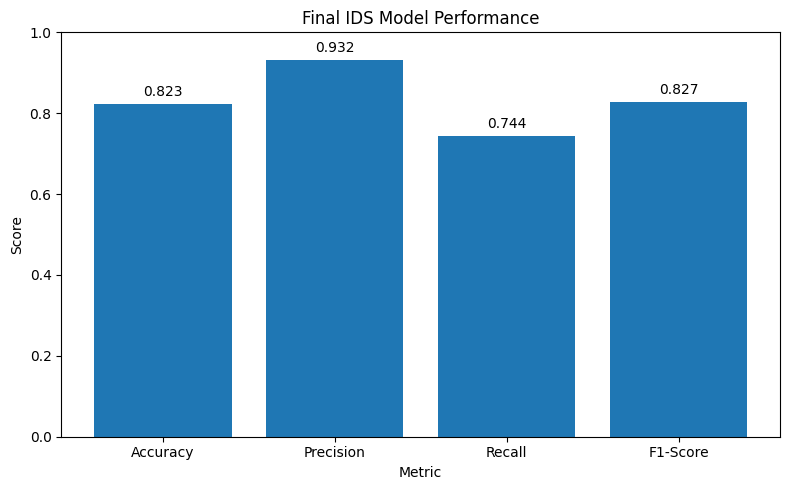

In [77]:
# ============================================================
# FINAL PERFORMANCE METRICS CHART
# ============================================================

metrics_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

metrics_values = [
    accuracy,
    precision,
    recall,
    f1
]

plt.figure(figsize=(8, 5))

plt.bar(
    metrics_names,
    metrics_values
)

plt.ylim(0, 1)

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Final IDS Model Performance")

# Display values above bars
for i, value in enumerate(metrics_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

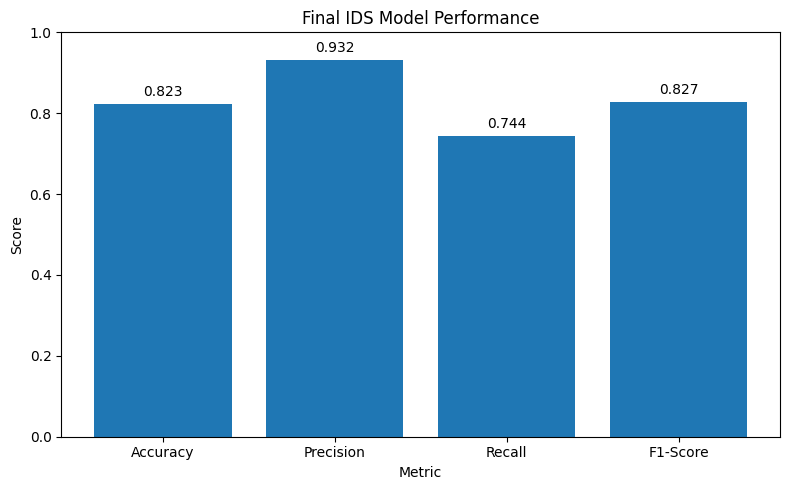

Performance chart saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_performance_metrics.png


In [78]:
# ============================================================
# SAVE FINAL PERFORMANCE CHART
# ============================================================

metrics_chart_file = (
    project_path + "/models/final_performance_metrics.png"
)

plt.figure(figsize=(8, 5))

plt.bar(
    metrics_names,
    metrics_values
)

plt.ylim(0, 1)

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Final IDS Model Performance")

for i, value in enumerate(metrics_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    metrics_chart_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance chart saved successfully!")
print(metrics_chart_file)

In [79]:
# ============================================================
# CONFUSION MATRIX TABLE
# ============================================================

confusion_table = pd.DataFrame(
    confusion_matrix,
    index=["Actual Normal", "Actual Attack"],
    columns=["Predicted Normal", "Predicted Attack"]
)

print("=" * 60)
print("FINAL CONFUSION MATRIX TABLE")
print("=" * 60)

display(confusion_table)

FINAL CONFUSION MATRIX TABLE


,Predicted Normal,Predicted Attack
Actual Normal,9017,693
Actual Attack,3287,9546


In [80]:
# ============================================================
# SAVE CONFUSION MATRIX TABLE
# ============================================================

confusion_table_file = (
    project_path + "/models/confusion_matrix_table.csv"
)

confusion_table.to_csv(
    confusion_table_file
)

print("Confusion matrix table saved successfully!")
print(confusion_table_file)

Confusion matrix table saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/confusion_matrix_table.csv


In [81]:
# ============================================================
# SAVE FINAL PERFORMANCE METRICS
# ============================================================

performance_metrics = {
    "Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1_Score": float(f1)
}

performance_metrics_file = (
    project_path + "/models/final_performance_metrics.json"
)

with open(performance_metrics_file, "w") as f:
    json.dump(performance_metrics, f, indent=4)

print("Final performance metrics saved successfully!")
print(performance_metrics_file)

print("\nFinal Metrics:")
for metric, value in performance_metrics.items():
    print(f"{metric}: {value:.4f}")

Final performance metrics saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_performance_metrics.json

Final Metrics:
Accuracy: 0.8234
Precision: 0.9323
Recall: 0.7439
F1_Score: 0.8275


In [82]:
# ============================================================
# FINAL MODEL EVALUATION SUMMARY
# ============================================================

print("=" * 70)
print("FINAL IDS MODEL EVALUATION SUMMARY")
print("=" * 70)

print(f"Dataset                 : NSL-KDD")
print(f"Classification          : Binary")
print(f"Original Features       : 122")
print(f"MVO Selected Features   : {len(selected_feature_indices)}")

print("\nCNN-BiGRU-Attention")
print(f"CNN Filters             : 64")
print(f"CNN Kernel Size         : 3")
print(f"BiGRU Units             : {best_gru_units}")

print("\nALO Hyperparameters")
print(f"Learning Rate            : {best_learning_rate}")
print(f"Dropout                  : {best_dropout}")

print("\nFinal Test Performance")
print(f"Test Loss                : {test_loss:.4f}")
print(f"Accuracy                 : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision                : {precision:.4f}")
print(f"Recall                   : {recall:.4f}")
print(f"F1-Score                 : {f1:.4f}")

print("\nConfusion Matrix")
print(confusion_table)

print("=" * 70)
print("FINAL EVALUATION COMPLETED")
print("=" * 70)

FINAL IDS MODEL EVALUATION SUMMARY
Dataset                 : NSL-KDD
Classification          : Binary
Original Features       : 122
MVO Selected Features   : 33

CNN-BiGRU-Attention
CNN Filters             : 64
CNN Kernel Size         : 3
BiGRU Units             : 106

ALO Hyperparameters
Learning Rate            : 0.007316
Dropout                  : 0.265

Final Test Performance
Test Loss                : 0.5604
Accuracy                 : 0.8234 (82.34%)
Precision                : 0.9323
Recall                   : 0.7439
F1-Score                 : 0.8275

Confusion Matrix
               Predicted Normal  Predicted Attack
Actual Normal              9017               693
Actual Attack              3287              9546
FINAL EVALUATION COMPLETED


In [83]:
# ============================================================
# SAVE FINAL EVALUATION SUMMARY
# ============================================================

evaluation_summary_file = (
    project_path + "/models/final_evaluation_summary.txt"
)

with open(evaluation_summary_file, "w") as f:

    f.write("=" * 70 + "\n")
    f.write("FINAL IDS MODEL EVALUATION SUMMARY\n")
    f.write("=" * 70 + "\n\n")

    f.write("Dataset                 : NSL-KDD\n")
    f.write("Classification          : Binary\n")
    f.write(f"Original Features       : 122\n")
    f.write(f"MVO Selected Features   : {len(selected_feature_indices)}\n\n")

    f.write("CNN-BiGRU-Attention\n")
    f.write("CNN Filters             : 64\n")
    f.write("CNN Kernel Size         : 3\n")
    f.write(f"BiGRU Units             : {best_gru_units}\n\n")

    f.write("ALO Hyperparameters\n")
    f.write(f"Learning Rate            : {best_learning_rate}\n")
    f.write(f"Dropout                  : {best_dropout}\n\n")

    f.write("Final Test Performance\n")
    f.write(f"Test Loss                : {test_loss:.4f}\n")
    f.write(f"Accuracy                 : {accuracy:.4f} ({accuracy * 100:.2f}%)\n")
    f.write(f"Precision                : {precision:.4f}\n")
    f.write(f"Recall                   : {recall:.4f}\n")
    f.write(f"F1-Score                 : {f1:.4f}\n\n")

    f.write("Confusion Matrix\n")
    f.write(str(confusion_table))
    f.write("\n\n")

    f.write("=" * 70 + "\n")
    f.write("END OF FINAL EVALUATION SUMMARY\n")
    f.write("=" * 70 + "\n")

print("Final evaluation summary saved successfully!")
print(evaluation_summary_file)

Final evaluation summary saved successfully!
/content/drive/MyDrive/Enhanced_IDS_Project/models/final_evaluation_summary.txt


In [84]:
# ============================================================
# FINAL PROJECT FILE CHECK
# ============================================================

import os

required_files = [
    "processed_data/X_train_normalized.npy",
    "processed_data/X_test_normalized.npy",
    "processed_data/y_train.npy",
    "processed_data/y_test.npy",

    "mvo_results/selected_feature_indices.npy",
    "mvo_results/best_feature_mask.npy",
    "mvo_results/best_fitness.npy",

    "alo_results/best_learning_rate.npy",
    "alo_results/best_gru_units.npy",
    "alo_results/best_dropout.npy",
    "alo_results/best_fitness.npy",

    "models/final_cnn_bigru_attention_alo.keras",
    "models/final_model_results.json",
    "models/final_metrics.json",
    "models/final_results_table.csv",
    "models/confusion_matrix_table.csv",
    "models/final_performance_metrics.json",

    "models/final_performance_metrics.png",
    "models/final_confusion_matrix.png",
    "models/final_training_validation_accuracy.png",
    "models/final_training_validation_loss.png",
    "models/project_workflow_diagram.png",

    "shap_results/shap_feature_importance.csv",
    "shap_results/top15_shap_features.csv",
    "shap_results/shap_feature_importance.png",
    "shap_results/top10_shap_features.txt"
]

print("=" * 70)
print("FINAL PROJECT FILE CHECK")
print("=" * 70)

missing_files = []

for file in required_files:

    full_path = os.path.join(project_path, file)

    if os.path.exists(full_path):
        print("✓", file)
    else:
        print("✗ MISSING:", file)
        missing_files.append(file)

print("\n" + "=" * 70)

if len(missing_files) == 0:
    print("ALL REQUIRED PROJECT FILES ARE PRESENT!")
else:
    print(f"{len(missing_files)} FILE(S) ARE MISSING.")

print("=" * 70)

FINAL PROJECT FILE CHECK
✓ processed_data/X_train_normalized.npy
✓ processed_data/X_test_normalized.npy
✓ processed_data/y_train.npy
✓ processed_data/y_test.npy
✓ mvo_results/selected_feature_indices.npy
✓ mvo_results/best_feature_mask.npy
✓ mvo_results/best_fitness.npy
✓ alo_results/best_learning_rate.npy
✓ alo_results/best_gru_units.npy
✓ alo_results/best_dropout.npy
✓ alo_results/best_fitness.npy
✓ models/final_cnn_bigru_attention_alo.keras
✓ models/final_model_results.json
✓ models/final_metrics.json
✓ models/final_results_table.csv
✓ models/confusion_matrix_table.csv
✓ models/final_performance_metrics.json
✓ models/final_performance_metrics.png
✗ MISSING: models/final_confusion_matrix.png
✓ models/final_training_validation_accuracy.png
✓ models/final_training_validation_loss.png
✓ models/project_workflow_diagram.png
✓ shap_results/shap_feature_importance.csv
✓ shap_results/top15_shap_features.csv
✓ shap_results/shap_feature_importance.png
✓ shap_results/top10_shap_features.txt

1 

In [85]:
# ============================================================
# FINAL PROJECT WORKFLOW SUMMARY
# ============================================================

workflow = """
ENHANCED INTRUSION DETECTION SYSTEM
====================================

1. NSL-KDD DATASET
        ↓
2. DATA PREPROCESSING
   - Remove difficulty column
   - Encode categorical features
   - Mean normalization
        ↓
3. MVO FEATURE SELECTION
   - Search for important features
   - Reduce 122 features to 33 features
        ↓
4. CNN FEATURE EXTRACTION
   - Conv1D
   - MaxPooling
        ↓
5. BiGRU SEQUENCE LEARNING
   - Bidirectional GRU
        ↓
6. ATTENTION MECHANISM
   - Focus on important feature representations
        ↓
7. ALO HYPERPARAMETER TUNING
   - Learning rate
   - GRU units
   - Dropout
        ↓
8. FINAL CNN-BiGRU-ATTENTION MODEL
        ↓
9. BINARY CLASSIFICATION
   - Normal = 0
   - Attack = 1
        ↓
10. MODEL EVALUATION
    - Accuracy
    - Precision
    - Recall
    - F1-Score
    - Confusion Matrix
        ↓
11. SHAP EXPLAINABILITY
    - Feature importance
    - Explain model predictions
"""

print(workflow)


ENHANCED INTRUSION DETECTION SYSTEM

1. NSL-KDD DATASET
        ↓
2. DATA PREPROCESSING
   - Remove difficulty column
   - Encode categorical features
   - Mean normalization
        ↓
3. MVO FEATURE SELECTION
   - Search for important features
   - Reduce 122 features to 33 features
        ↓
4. CNN FEATURE EXTRACTION
   - Conv1D
   - MaxPooling
        ↓
5. BiGRU SEQUENCE LEARNING
   - Bidirectional GRU
        ↓
6. ATTENTION MECHANISM
   - Focus on important feature representations
        ↓
7. ALO HYPERPARAMETER TUNING
   - Learning rate
   - GRU units
   - Dropout
        ↓
8. FINAL CNN-BiGRU-ATTENTION MODEL
        ↓
9. BINARY CLASSIFICATION
   - Normal = 0
   - Attack = 1
        ↓
10. MODEL EVALUATION
    - Accuracy
    - Precision
    - Recall
    - F1-Score
    - Confusion Matrix
        ↓
11. SHAP EXPLAINABILITY
    - Feature importance
    - Explain model predictions

